# Digital Banking Fraud Risk and Customer Experience
### QM640 Data Analytics Capstone: complete analysis notebook

**Student:** Kamakya C · **Mentor:** Ms. Keya Choudhury Ganguli · Walsh College, Fall 2026 Term

This notebook runs the whole analysis behind the interim report, step by step, from the raw survey file to the preliminary results. It replaces running the separate scripts in `src/` (`prep.py`, `01_sample_size.py` to `05_sensitivity.py`) and gives the same numbers.

**Business problem.** How can banks balance fraud protection, financial-loss prevention, and customer experience as digital banking grows?

| RQ | Question | Outcome | Method |
|---|---|---|---|
| RQ1 | Are mobile, online, P2P and automated-chat use associated with fraud experience, after controlling for customer characteristics? | `FRAUD_EXP` | Chi-square, logistic regression |
| RQ2 | Among fraud victims, are the fraud channel, scam type, bank detection and repeat victimization associated with money being taken? | `FIN_LOSS` | Chi-square, logistic regression |
| RQ3 | Are digital-banking use and institution type associated with false-positive fraud interventions, after controlling for fraud experience? | `FALSE_POS` | Chi-square, logistic regression |
| RQ4 | Can machine-learning models predict fraud experience well enough to form risk segments? | `FRAUD_EXP` | Logistic regression, Random Forest, Gradient Boosting |

**Steps**
1. Setup and data loading
2. Variable derivation
3. Data cleaning
4. Sample-size calculation
5. Exploratory data analysis (EDA)
6. RQ1 to RQ3: logistic regression
7. RQ4: machine-learning models and risk segments
8. Sensitivity check: RQ4 without account alerts
9. Mentor feedback on RQ4: more inputs, precision and recall, false positives and false negatives
10. Summary of findings

**How to run.** In Google Colab or Jupyter, choose *Run all*. The notebook finds the data file in the repository, or downloads it from GitHub if it is not found. The full run takes about 10 minutes; steps 7 and 9 are the slowest. Random seeds are fixed (640), so results are reproducible.

## 1. Setup and data loading

Imports, plotting style, and the data file. The data are the CFPB National Age-Friendly Banking Survey (NAFBS) public use file: 2,721 U.S. adults with a bank or credit union account, surveyed January 9 to February 9, 2024.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from math import sqrt, ceil, log, exp
from scipy.stats import norm, chi2, chi2_contingency, fisher_exact
from scipy.optimize import brentq
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, precision_score, recall_score,
                             f1_score, accuracy_score, confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50); pd.set_option('display.width', 200)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
DARK, MID, LIGHT, ACC = '#1f3b5c', '#5b84b1', '#b9cde5', '#c0504d'
SEED = 640

# ---- locate the raw file (repository root, notebooks/ folder, or Colab), else download it from GitHub
FNAME = 'cfpb_nafbs-puf-labeled_2026-02.csv'
URL = 'https://raw.githubusercontent.com/Kamakya/qm640-digital-banking-fraud-risk/main/data/raw/' + FNAME
candidates = [os.path.join('data', 'raw', FNAME), os.path.join('..', 'data', 'raw', FNAME), FNAME]
RAW = next((p for p in candidates if os.path.exists(p)), URL)
ROOT = os.path.dirname(os.path.dirname(os.path.dirname(RAW))) if RAW != URL and RAW != FNAME else '.'
OUT = os.path.join(ROOT, 'outputs'); os.makedirs(OUT, exist_ok=True)
print('Reading data from:', RAW)
raw = pd.read_csv(RAW, low_memory=False)
print('Rows, columns:', raw.shape)
raw[['CASEID', 'WEIGHT_FINAL', 'TYPE', 'MOBILE', 'ACC2_6', 'FRAUD1', 'FRAUD8', 'AGE4']].head(8)

Reading data from: ../data/raw/cfpb_nafbs-puf-labeled_2026-02.csv
Rows, columns: (2721, 284)


,CASEID,WEIGHT_FINAL,TYPE,MOBILE,ACC2_6,FRAUD1,FRAUD8,AGE4
0,59,7.029865,Bank,Yes,Yes,One time,Never,18-29
1,69,0.562469,Bank,Yes,No,One time,One time,30-44
2,70,0.142190,Bank,Yes,No,Never,Never,60+
3,71,0.446907,Credit Union,No,No,Never,Never,60+
4,73,0.356319,Bank,Yes,Yes,Never,Two or three times,60+
5,76,0.268264,Bank,Yes,No,One time,One time,18-29
6,81,0.324067,Bank,Yes,No,Never,Never,60+
7,82,0.207755,Bank,No,No,One time,Never,60+


## 2. Variable derivation

The labeled file stores answers as text. This step converts the items used in the study into analysis variables (the same rules as `src/prep.py`):

* **Outcomes:** `FRAUD_EXP` (fraud or scam at least once in the past year), `FIN_LOSS` (money taken from the account, victims only), `UNREC_LOSS` (loss not fully recovered), `FALSE_POS` (an intervention that turned out not to be fraud).
* **Focal predictors:** digital-banking use, institution type, and incident characteristics for victims.
* **Controls:** age, sex, race and ethnicity (collapsed to 4 groups), education (4 levels), household income.

Special answers such as *I'm not sure* or *skipped* become missing (`NaN`), because they cannot be coded as yes or no.

In [2]:
YN = {'Yes': 1, 'No': 0}
TIMES = {'Never': 0, 'One time': 1, 'Two or three times': 1, 'More than three times': 1}

def load(df):
    d = df.copy()
    for c in d.columns:
        if d[c].dtype == object: d[c] = d[c].str.strip()
    # outcomes
    d['FRAUD_EXP'] = d.FRAUD1.map(TIMES)                      # "I'm not sure" / skipped -> NaN
    d['FALSE_POS'] = d.FRAUD8.map(TIMES)
    f2 = d.FRAUD2.fillna('')
    d['FIN_LOSS'] = np.where(f2.str.startswith('I lost money'), 1.0, np.where(f2.str.startswith('No money'), 0.0, np.nan))
    d['UNREC_LOSS'] = np.where(f2.str.contains('some of it|none of it'), 1.0,
                        np.where(f2.str.startswith('No money') | f2.str.contains('all of it'), 0.0, np.nan))
    # focal predictors
    d['MOBILE_USE'] = d.MOBILE.map(YN); d['WEB_USE'] = d.WEB.map(YN)
    d['P2P_USE'] = d.ACC2_6.map(YN); d['CHAT_USE'] = d.ACC2_5.map(YN); d['ALERT_USE'] = d.ALERT_1.map(YN)
    d['CREDIT_UNION'] = d.TYPE.map({'Credit Union': 1, 'Bank': 0, 'Online-only bank': 0})
    d['BIG_BANK'] = d.BIGBANK.map(YN)
    d['DEBIT_INVOLVED'] = d.FRAUD3_1.map(YN); d['BANK_DETECTED'] = d.FRAUD5_1.map(YN)
    d['REPEAT_VICTIM'] = d.FRAUD1.map({'One time': 0, 'Two or three times': 1, 'More than three times': 1})
    d['PHISHING'] = d.SCAM_3.map(YN)
    # controls
    d['RACE4'] = d.RACETHNICITY.replace({'White, non-Hispanic': 'White NH', 'Black, non-Hispanic': 'Black NH', 'Hispanic': 'Hispanic'})
    d.loc[~d.RACE4.isin(['White NH', 'Black NH', 'Hispanic']), 'RACE4'] = 'Other NH'
    d['EDUC4'] = d.EDUC5.replace({'Less than HS': 'HS or less', 'HS graduate or equivalent': 'HS or less',
        'Some college/ associates degree': 'Some college', "Bachelor's degree": 'Bachelor', 'Post grad study/professional degree': 'Postgraduate'})
    ag = ['Strongly agree', 'Somewhat agree', 'Neither agree nor disagree', 'Somewhat disagree', 'Strongly disagree']
    d['TRUST_HIGH'] = np.where(d.TRUST1.isin(ag), (d.TRUST1 == 'Strongly agree').astype(float), np.nan)
    return d

d = load(raw)
derived = ['FRAUD_EXP', 'FIN_LOSS', 'UNREC_LOSS', 'FALSE_POS', 'MOBILE_USE', 'WEB_USE', 'P2P_USE', 'CHAT_USE', 'ALERT_USE',
           'CREDIT_UNION', 'DEBIT_INVOLVED', 'BANK_DETECTED', 'REPEAT_VICTIM', 'PHISHING', 'TRUST_HIGH']
summary = pd.DataFrame({'valid n': d[derived].notna().sum(), 'missing': d[derived].isna().sum(),
                        'share = 1': d[derived].mean().round(3)})
summary

,valid n,missing,share = 1
FRAUD_EXP,2529,192,0.267
FIN_LOSS,642,2079,0.528
UNREC_LOSS,642,2079,0.139
FALSE_POS,2702,19,0.276
MOBILE_USE,2704,17,0.645
WEB_USE,2707,14,0.581
P2P_USE,2721,0,0.294
CHAT_USE,2721,0,0.175
ALERT_USE,2721,0,0.606
CREDIT_UNION,2687,34,0.251


**Reading the table.** `FIN_LOSS`, `DEBIT_INVOLVED`, `BANK_DETECTED`, `REPEAT_VICTIM` and `PHISHING` are missing for most rows because the survey asked those items only of the 675 fraud victims. That is *structural* missingness, by design, not data loss.

## 3. Data cleaning

Four checks: duplicates, special responses (missing values), logical consistency with the survey routing, and outliers.

### 3.1 Duplicates

In [3]:
print('Exact duplicate rows:          ', raw.duplicated().sum())
print('Duplicate respondent IDs:      ', raw.CASEID.duplicated().sum())
print('Duplicates ignoring the ID:    ', raw.drop(columns=['CASEID']).duplicated().sum())

Exact duplicate rows:           0
Duplicate respondent IDs:       0
Duplicates ignoring the ID:     0


No duplicates of any kind, so every row is a distinct respondent and no rows are removed.

### 3.2 Special responses (missing values)

,asked,not_asked_by_design,special_responses,pct_special
item,,,,
FRAUD1,2721,0,192,7.06
BIGBANK,2721,0,138,5.07
FRAUD2,675,2046,33,4.89
TYPE,2721,0,34,1.25
DEVICE2,2721,0,25,0.92
FRAUD8,2721,0,19,0.70
MOBILE,2721,0,17,0.62
WEB,2721,0,14,0.51
TRUST1,2721,0,10,0.37


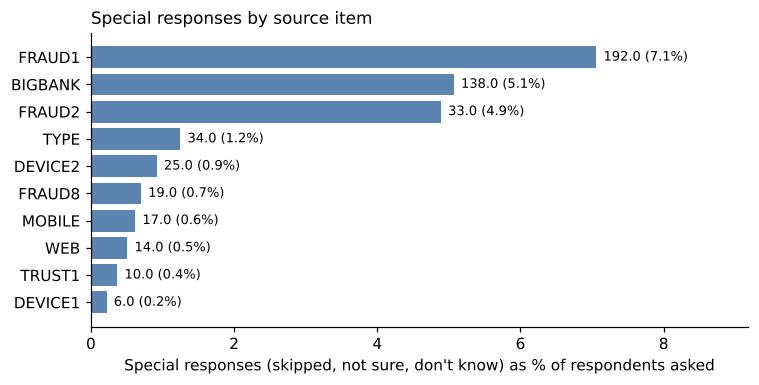

In [4]:
SPECIAL = ['SKIPPED ON WEB', "DON'T KNOW", 'REFUSED', "I'm not sure", 'Unknown', 'I don’t know.']
src = ['FRAUD1', 'FRAUD2', 'FRAUD8', 'MOBILE', 'WEB', 'ACC2_5', 'ACC2_6', 'ALERT_1', 'TYPE', 'BIGBANK', 'DEVICE1', 'DEVICE2',
       'AGE4', 'SEX', 'RACETHNICITY', 'EDUC5', 'INCOME4', 'URBAN3', 'TRUST1', 'FRAUD3_1', 'FRAUD5_1', 'SCAM_3']
rows = []
for c in src:
    s = raw[c].astype(str).str.strip()
    victim_only = c in ['FRAUD2', 'FRAUD3_1', 'FRAUD5_1', 'SCAM_3']
    blank = int((s == '').sum() + raw[c].isna().sum())
    spec = int(s.isin(SPECIAL).sum())
    base = len(raw) - blank if victim_only else len(raw)
    rows.append(dict(item=c, asked=base, not_asked_by_design=blank, special_responses=spec, pct_special=round(100 * spec / base, 2)))
miss = pd.DataFrame(rows).set_index('item').sort_values('pct_special', ascending=False)
display(miss)

mm = miss[miss.special_responses > 0].sort_values('pct_special')
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(mm.index, mm.pct_special, color=MID)
for i, (k, r) in enumerate(mm.iterrows()): ax.text(r.pct_special + .1, i, f'{r.special_responses} ({r.pct_special:.1f}%)', va='center', fontsize=8.5)
ax.set_xlabel("Special responses (skipped, not sure, don't know) as % of respondents asked"); ax.set_xlim(0, mm.pct_special.max() * 1.3)
ax.set_title('Special responses by source item', loc='left', fontsize=11)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig_missing.png'), dpi=200); plt.show()

**Interpretation.** Missingness is concentrated in the fraud question itself: 192 respondents (7.1%) were not sure whether they had experienced fraud or skipped the item, leaving 2,529 valid cases for RQ1 and RQ4. Every predictor is at least 98.7% complete. **Treatment:** special responses are set to missing; RQ1 to RQ3 use complete cases, and RQ4 imputes the most frequent category *inside each training fold* (to avoid leakage). `BIGBANK` is used only descriptively.

### 3.3 Logical consistency with the survey routing

In [5]:
victim = d.FRAUD1.isin(['One time', 'Two or three times', 'More than three times'])
answered_f2 = raw.FRAUD2.astype(str).str.strip() != ''
print('Fraud victims (FRAUD1 = at least once):', victim.sum())
print('Respondents who answered FRAUD2:       ', answered_f2.sum())
print('Non-victims who answered FRAUD2:       ', (answered_f2 & ~victim).sum())

Fraud victims (FRAUD1 = at least once): 675
Respondents who answered FRAUD2:        675
Non-victims who answered FRAUD2:        0


The loss items were answered by exactly the 675 victims and by no non-victims, which confirms the routing rule used to derive `FIN_LOSS`.

### 3.4 Outliers: the survey weight
`WEIGHT_FINAL` is the only continuous analysis variable. Outliers are flagged with the interquartile range (IQR) rule.

count    2721.000
mean        1.000
std         1.269
min         0.027
25%         0.271
50%         0.472
75%         1.152
max        10.209

Upper IQR fence: 2.47  ->  314 weights flagged (11.5%)
Of these, respondents under 60: 309
Design effect of the weights: 2.61


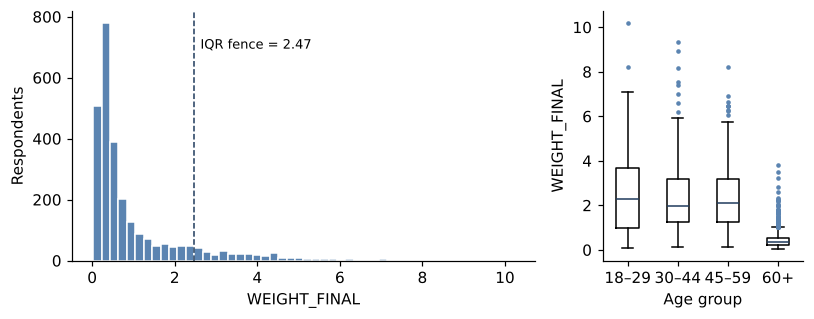

In [6]:
w = raw.WEIGHT_FINAL
q1, q3 = w.quantile(.25), w.quantile(.75); fence = q3 + 1.5 * (q3 - q1)
out_w = w > fence
print(w.describe().round(3).to_string())
print(f'\nUpper IQR fence: {fence:.2f}  ->  {out_w.sum()} weights flagged ({100 * out_w.mean():.1f}%)')
print('Of these, respondents under 60:', (out_w & (raw.AGE4 != '60+')).sum())
print(f'Design effect of the weights: {1 + (w.std(ddof=0) / w.mean()) ** 2:.2f}')

fig, ax = plt.subplots(1, 2, figsize=(7.5, 3), gridspec_kw={'width_ratios': [3, 1.3]})
ax[0].hist(w, bins=50, color=MID, edgecolor='white'); ax[0].axvline(fence, color=DARK, ls='--', lw=1)
ax[0].text(fence + .15, ax[0].get_ylim()[1] * .85, f'IQR fence = {fence:.2f}', fontsize=8.5)
ax[0].set_xlabel('WEIGHT_FINAL'); ax[0].set_ylabel('Respondents')
ax[1].boxplot([w[raw.AGE4 == a] for a in ['18-29', '30-44', '45-59', '60+']], tick_labels=['18–29', '30–44', '45–59', '60+'],
              flierprops=dict(markersize=2, markerfacecolor=MID, markeredgecolor=MID), medianprops=dict(color=DARK))
ax[1].set_xlabel('Age group'); ax[1].set_ylabel('WEIGHT_FINAL')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig_weights.png'), dpi=200); plt.show()

**Interpretation.** 314 weights (11.5%) exceed the fence, and 309 of them belong to adults under 60. Because the survey **oversampled adults aged 60 and older**, younger adults get large weights by design, so these are not errors. **Treatment:** weights are kept untrimmed; the main models are unweighted with age as a control, and weighted models are a sensitivity check.

### 3.5 Cleaning log and processed file

In [7]:
log_tbl = pd.DataFrame([
    ['Duplicates', 'All rows; CASEID', 'Exact duplicates, duplicate IDs', 'None found; no action'],
    ['Special responses in outcomes', 'FRAUD1, FRAUD2, FRAUD8', 'Frequency tables', 'Set to missing (192, 33, 19)'],
    ['Missing predictors', 'MOBILE, WEB, TYPE, DEVICE1/2, TRUST1', 'isna counts after recoding', 'Complete cases (RQ1-RQ3); fold-wise mode imputation (RQ4)'],
    ['Structural missingness', 'FRAUD2-FRAUD6, SCAM items', 'Cross-tab against FRAUD1', 'Kept as not applicable; defines the RQ2 subgroup'],
    ['Outliers', 'WEIGHT_FINAL', 'IQR rule (Q3 + 1.5 IQR)', '314 flagged; kept (oversample design)'],
    ['Category sparsity', 'RACETHNICITY, EDUC5', 'Cell counts', 'Collapsed to RACE4 and EDUC4'],
    ['Logical consistency', 'FRAUD1 vs FRAUD2', 'Victims vs loss answers', 'No inconsistencies'],
], columns=['Issue', 'Variables', 'Detection', 'Treatment'])
display(log_tbl)

keep = ['CASEID', 'WEIGHT_FINAL', 'FRAUD_EXP', 'FIN_LOSS', 'UNREC_LOSS', 'FALSE_POS', 'MOBILE_USE', 'WEB_USE', 'P2P_USE', 'CHAT_USE', 'ALERT_USE',
        'CREDIT_UNION', 'DEBIT_INVOLVED', 'BANK_DETECTED', 'REPEAT_VICTIM', 'PHISHING', 'TRUST_HIGH', 'AGE4', 'SEX', 'RACE4', 'EDUC4', 'INCOME4',
        'TYPE', 'DEVICE1', 'DEVICE2', 'URBAN3']
PROC = os.path.join(ROOT, 'data', 'processed'); os.makedirs(PROC, exist_ok=True)
d[keep].to_csv(os.path.join(PROC, 'nafbs_analysis.csv'), index=False)
print('Processed file saved:', os.path.join(PROC, 'nafbs_analysis.csv'), d[keep].shape)

,Issue,Variables,Detection,Treatment
0,Duplicates,All rows; CASEID,"Exact duplicates, duplicate IDs",None found; no action
1,Special responses in outcomes,"FRAUD1, FRAUD2, FRAUD8",Frequency tables,"Set to missing (192, 33, 19)"
2,Missing predictors,"MOBILE, WEB, TYPE, DEVICE1/2, TRUST1",isna counts after recoding,Complete cases (RQ1-RQ3); fold-wise mode imput...
3,Structural missingness,"FRAUD2-FRAUD6, SCAM items",Cross-tab against FRAUD1,Kept as not applicable; defines the RQ2 subgroup
4,Outliers,WEIGHT_FINAL,IQR rule (Q3 + 1.5 IQR),314 flagged; kept (oversample design)
5,Category sparsity,"RACETHNICITY, EDUC5",Cell counts,Collapsed to RACE4 and EDUC4
6,Logical consistency,FRAUD1 vs FRAUD2,Victims vs loss answers,No inconsistencies


Processed file saved: ../data/processed/nafbs_analysis.csv (2721, 26)


## 4. Sample-size calculation

**RQ1 to RQ3** test a binary predictor in a multivariable logistic regression, so each uses the power method of Hsieh, Bloch and Larsen (1998): α = .05 (two-sided), power = .80, smallest odds ratio of interest OR = 1.50 (RQ1, RQ3) or 1.75 (RQ2, smaller subgroup). With $P_1$ the event rate without the predictor, $B$ the share with it and $\rho^2$ its squared correlation with the controls:

$$P_2 = \frac{OR \cdot P_1}{1 - P_1 + OR \cdot P_1}, \qquad \bar P = (1-B)P_1 + B P_2$$

$$n = \frac{\left[z_{1-\alpha/2}\sqrt{\bar P(1-\bar P)/B} + z_{1-\beta}\sqrt{P_1(1-P_1) + P_2(1-P_2)(1-B)/B}\right]^2}{(P_1-P_2)^2(1-B)}, \qquad N = \frac{n}{1-\rho^2}$$

Both OR and 1/OR are computed and the larger N is kept; the predictor needing the largest N governs each RQ.

**RQ4** is a prediction model, so it uses the three criteria of Riley et al. (2019).

In [8]:
CONTROLS_SS = 'C(AGE4) + C(SEX) + C(RACE4) + C(EDUC4) + C(INCOME4)'
za, zb = norm.ppf(.975), norm.ppf(.80)

def hsieh(P1, OR, B, rho2):
    o = P1 / (1 - P1); P2 = OR * o / (1 + OR * o); Pb = (1 - B) * P1 + B * P2
    A = za * sqrt(Pb * (1 - Pb) / B); C = zb * sqrt(P1 * (1 - P1) + P2 * (1 - P2) * (1 - B) / B)
    n0 = (A + C) ** 2 / ((P1 - P2) ** 2 * (1 - B))
    return dict(P1=P1, P2=P2, B=B, n_unadj=n0, rho2=rho2, N=ceil(n0 / (1 - rho2)))

def focal_n(y, x, sub, OR, extra=''):
    t = sub[[y, x]].dropna(); a = t[t[x] == 1][y]; b = t[t[x] == 0][y]
    r2 = smf.ols(f'{x} ~ {CONTROLS_SS}{extra}', data=sub.dropna(subset=[y, x])).fit().rsquared
    r2r = ceil(r2 * 20) / 20                                   # round up to the next .05
    up, dn = hsieh(b.mean(), OR, len(a) / len(t), r2r), hsieh(b.mean(), 1 / OR, len(a) / len(t), r2r)
    return dict(valid_n=len(t), P1=round(b.mean(), 3), B=round(len(a) / len(t), 3), rho2=r2r, N_at_OR=up['N'], N_at_1_over_OR=dn['N'], required_N=max(up['N'], dn['N']))

rq1 = d.dropna(subset=['FRAUD_EXP']); vic = d.dropna(subset=['FIN_LOSS']); rq3 = d.dropna(subset=['FALSE_POS', 'FRAUD_EXP'])
ss = []
for x in ['MOBILE_USE', 'WEB_USE', 'P2P_USE', 'CHAT_USE']: ss.append(dict(RQ='RQ1', predictor=x, **focal_n('FRAUD_EXP', x, rq1, 1.5)))
for x in ['DEBIT_INVOLVED', 'BANK_DETECTED', 'REPEAT_VICTIM', 'PHISHING']: ss.append(dict(RQ='RQ2', predictor=x, **focal_n('FIN_LOSS', x, vic, 1.75)))
for x in ['MOBILE_USE', 'WEB_USE', 'P2P_USE', 'CHAT_USE', 'CREDIT_UNION']: ss.append(dict(RQ='RQ3', predictor=x, **focal_n('FALSE_POS', x, rq3, 1.5, ' + FRAUD_EXP')))
ss = pd.DataFrame(ss); display(ss)

# RQ4: Riley et al. (2019)
phi = d.FRAUD_EXP.mean(); lnL0 = phi * log(phi) + (1 - phi) * log(1 - phi); maxR2 = 1 - exp(2 * lnL0)
R2 = 0.15 * maxR2; S = 0.9; P = 24
c1 = P / ((S - 1) * log(1 - R2 / S)); S2 = R2 / (R2 + 0.05 * maxR2); c2 = P / ((S2 - 1) * log(1 - R2 / S2)); c3 = (1.96 / .05) ** 2 * phi * (1 - phi)
print(f'RQ4: phi = {phi:.4f}, max R2_CS = {maxR2:.4f}, anticipated R2_CS = {R2:.4f}')
print(f'  criterion 1 (shrinkage .90): {ceil(c1):,}   criterion 2 (optimism): {ceil(c2):,}   criterion 3 (precision): {ceil(c3):,}')

final = ss.groupby('RQ').required_N.max().to_dict(); final['RQ4'] = ceil(max(c1, c2, c3))
avail = {'RQ1': int(d.FRAUD_EXP.notna().sum()), 'RQ2': int(d.FIN_LOSS.notna().sum()), 'RQ3': len(rq3), 'RQ4': round(.8 * d.FRAUD_EXP.notna().sum())}
display(pd.DataFrame({'minimum N': final, 'available N': avail}))
print('Final sample size N =', max(final.values()))

,RQ,predictor,valid_n,P1,B,rho2,N_at_OR,N_at_1_over_OR,required_N
0,RQ1,MOBILE_USE,2512,0.223,0.645,0.15,1294,1579,1579
1,RQ1,WEB_USE,2517,0.263,0.585,0.10,1042,1247,1247
2,RQ1,P2P_USE,2529,0.244,0.296,0.10,1242,1580,1580
3,RQ1,CHAT_USE,2529,0.245,0.176,0.05,1665,2157,2157
4,RQ2,DEBIT_INVOLVED,642,0.343,0.682,0.05,511,594,594
5,RQ2,BANK_DETECTED,642,0.569,0.450,0.05,466,430,466
6,RQ2,REPEAT_VICTIM,642,0.528,0.377,0.05,473,457,473
7,RQ2,PHISHING,642,0.563,0.280,0.05,571,526,571
8,RQ3,MOBILE_USE,2500,0.184,0.644,0.15,1468,1842,1842
9,RQ3,WEB_USE,2504,0.261,0.586,0.10,1047,1254,1254


RQ4: phi = 0.2669, max R2_CS = 0.6866, anticipated R2_CS = 0.1030
  criterion 1 (shrinkage .90): 1,975   criterion 2 (optimism): 650   criterion 3 (precision): 301


,minimum N,available N
RQ1,2157,2529
RQ2,594,642
RQ3,2147,2516
RQ4,1975,2023


Final sample size N = 2157


**Interpretation.** The largest requirement is **N = 2,157 (RQ1)**, and every analysis has more respondents than it needs (RQ4 is checked against its 2,023-respondent training partition). RQ2 is limited to the 642 victims with a valid loss answer, which is enough for OR = 1.75 but not for smaller effects.

## 5. Exploratory data analysis (EDA)

### 5.1 Sample profile

In [9]:
wt = d.WEIGHT_FINAL; rows = []
for var, label in [('AGE4', 'Age group'), ('SEX', 'Sex'), ('RACE4', 'Race and ethnicity'), ('INCOME4', 'Household income'),
                   ('TYPE', 'Institution type'), ('MOBILE', 'Mobile banking, past month'), ('ACC2_6', 'P2P payment service'), ('ACC2_5', 'Automated chat')]:
    for level in sorted(d[var].dropna().unique()):
        m = d[var] == level
        rows.append(dict(characteristic=label, level=level, n=int(m.sum()), unweighted_pct=round(100 * m.mean(), 1), weighted_pct=round(100 * wt[m].sum() / wt.sum(), 1)))
pd.DataFrame(rows).set_index(['characteristic', 'level'])

n  unweighted_pct  weighted_pct
characteristic             level                                                        
Age group                  18-29                       175             6.4          16.2
                           30-44                       318            11.7          27.4
                           45-59                       291            10.7          25.1
                           60+                        1937            71.2          31.3
Sex                        Female                     1477            54.3          50.9
                           Male                       1244            45.7          49.1
Race and ethnicity         Black NH                    263             9.7           9.7
                           Hispanic                    334            12.3          13.2
                           Other NH                    169             6.2           9.5
                           White NH                   1955            71.8          67.5
Household income           $100,000 or more            689            25.3          33.1
                           $30,000 to under $60,000    699            25.7          27.1
                           $60,000 to under $100,000   665            24.4          27.9
                           Less than $30,000           668            24.5          11.8
Institution type           Bank                       1894            69.6          69.0
                           Credit Union                674            24.8          23.9
                           I'm not sure                 27             1.0           0.7
                           Online-only bank            119             4.4           6.2
                           SKIPPED ON WEB                7             0.3           0.1
Mobile banking, past month No                          961            35.3          23.5
                           SKIPPED ON WEB               17             0.6           0.6
                           Yes                        1743            64.1          75.9
P2P payment service        No                         1922            70.6          65.8
                           Yes                         799            29.4          34.2
Automated chat             No                         2245            82.5          77.4
                           Yes                         476            17.5          22.6

Adults aged 60 and older are 71.2% of the sample but 31.3% of the weighted population: the oversample is why age is controlled in every model.

### 5.2 Helper functions
Rates use Wilson 95% confidence intervals; `chi()` runs a chi-square test with Cramér's V and the crude odds ratio.

In [10]:
def rate(sub, y, x=None):
    def one(s):
        s = s.dropna(); n = len(s); p = s.mean(); z = 1.96
        den = 1 + z * z / n; c = (p + z * z / (2 * n)) / den; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
        return dict(n=n, events=int(s.sum()), p=p, lo=c - h, hi=c + h)
    if x is None: return one(sub[y])
    return {k: one(g[y]) for k, g in sub.groupby(x)}

def chi(sub, y, x):
    t = sub[[x, y]].dropna(); tab = pd.crosstab(t[x], t[y])
    c2, p, dof, ex = chi2_contingency(tab, correction=False)
    out = dict(n=len(t), chi2=c2, df=dof, p=p, cramers_V=np.sqrt(c2 / (len(t) * (min(tab.shape) - 1))), min_expected=ex.min())
    if tab.shape == (2, 2) and 1 in tab.index:
        a, b, c, dd = tab.loc[1, 1], tab.loc[1, 0], tab.loc[0, 1], tab.loc[0, 0]
        out.update(rate_if_yes=a / (a + b), rate_if_no=c / (c + dd), crude_OR=a * dd / (b * c))
    return out

LAB = {'MOBILE_USE': 'Mobile banking', 'WEB_USE': 'Online banking', 'P2P_USE': 'P2P payments', 'CHAT_USE': 'Automated chat',
       'CREDIT_UNION': 'Credit union', 'DEBIT_INVOLVED': 'Debit card involved', 'BANK_DETECTED': 'Bank identified fraud',
       'REPEAT_VICTIM': 'Repeat victim (2+)', 'PHISHING': 'Phishing scam'}
F1 = ['MOBILE_USE', 'WEB_USE', 'P2P_USE', 'CHAT_USE']; F2 = ['DEBIT_INVOLVED', 'BANK_DETECTED', 'REPEAT_VICTIM', 'PHISHING']; F3 = F1 + ['CREDIT_UNION']

### 5.3 Prevalence of the outcomes

,n,events,p,lo,hi,weighted_p
FRAUD_EXP,2529.0,675.0,0.267,0.250,0.284,0.253
FIN_LOSS,642.0,339.0,0.528,0.489,0.566,0.579
UNREC_LOSS,642.0,89.0,0.139,0.114,0.168,0.138
FALSE_POS,2702.0,747.0,0.276,0.260,0.294,0.300


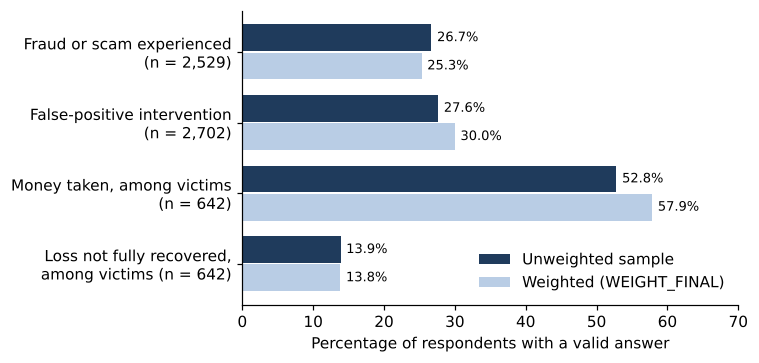

In [11]:
oc = {}
for y in ['FRAUD_EXP', 'FIN_LOSS', 'UNREC_LOSS', 'FALSE_POS']:
    r = rate(d, y); s = d.dropna(subset=[y]); r['weighted_p'] = np.average(s[y], weights=s.WEIGHT_FINAL); oc[y] = r
display(pd.DataFrame(oc).T.astype(float).round(3))

labs = [('FRAUD_EXP', f"Fraud or scam experienced\n(n = {oc['FRAUD_EXP']['n']:,})"), ('FALSE_POS', f"False-positive intervention\n(n = {oc['FALSE_POS']['n']:,})"),
        ('FIN_LOSS', f"Money taken, among victims\n(n = {oc['FIN_LOSS']['n']:,})"), ('UNREC_LOSS', f"Loss not fully recovered,\namong victims (n = {oc['UNREC_LOSS']['n']:,})")]
fig, ax = plt.subplots(figsize=(7, 3.4)); yy = np.arange(len(labs))[::-1]
u = [oc[k]['p'] * 100 for k, _ in labs]; wv = [oc[k]['weighted_p'] * 100 for k, _ in labs]
ax.barh(yy + .2, u, .38, color=DARK, label='Unweighted sample'); ax.barh(yy - .2, wv, .38, color=LIGHT, label='Weighted (WEIGHT_FINAL)')
for i in range(len(labs)): ax.text(u[i] + .8, yy[i] + .2, f'{u[i]:.1f}%', va='center', fontsize=8.5); ax.text(wv[i] + .8, yy[i] - .2, f'{wv[i]:.1f}%', va='center', fontsize=8.5)
ax.set_yticks(yy, [l for _, l in labs]); ax.set_xlabel('Percentage of respondents with a valid answer'); ax.set_xlim(0, 70); ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig_outcomes.png'), dpi=200); plt.show()

**Insight.** About 1 in 4 respondents (26.7%) experienced fraud, and slightly more (27.6%) had a false-positive intervention, so **friction is as common as fraud**. Among victims, 52.8% had money taken, but only 13.9% were left with an unrecovered loss.

### 5.4 Fraud and false positives by digital-banking behavior (RQ1, RQ3)

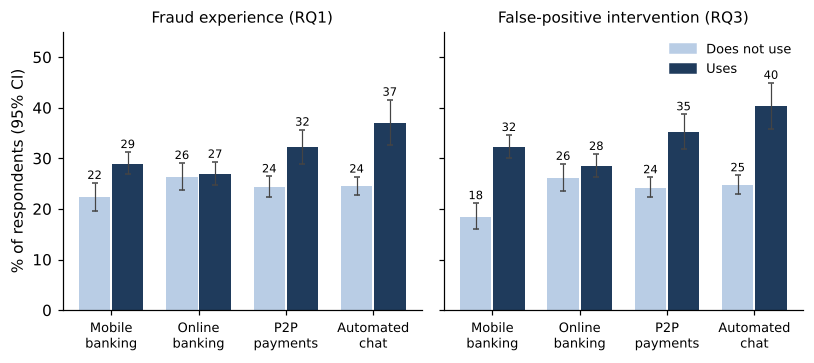

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(7.5, 3.4), sharey=True)
for ax, (y, sub, title) in zip(axs, [('FRAUD_EXP', rq1, 'Fraud experience (RQ1)'), ('FALSE_POS', rq3, 'False-positive intervention (RQ3)')]):
    for i, x in enumerate(F1):
        r = rate(sub, y, x)
        for j, (k, col) in enumerate([(0, LIGHT), (1, DARK)]):
            rr = r[k]; p = rr['p'] * 100
            ax.bar(i + (j - .5) * .38, p, .36, color=col, yerr=[[p - rr['lo'] * 100], [rr['hi'] * 100 - p]], capsize=2, ecolor='#444', error_kw=dict(lw=.8))
            ax.text(i + (j - .5) * .38, rr['hi'] * 100 + .8, f'{p:.0f}', ha='center', fontsize=7.5)
    ax.set_xticks(range(len(F1)), [LAB[x].replace(' ', '\n', 1) for x in F1], fontsize=8.5); ax.set_title(title, fontsize=10)
axs[0].set_ylabel('% of respondents (95% CI)'); axs[0].set_ylim(0, 55)
axs[1].legend([Patch(color=LIGHT), Patch(color=DARK)], ['Does not use', 'Uses'], frameon=False, loc='upper right', fontsize=8.5)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig_digital.png'), dpi=200); plt.show()

**Insight.** Users of automated chat, P2P payments and mobile banking report more fraud (37.0% vs. 24.5% for chat), and the same features show even larger gaps in false positives. Online banking shows no difference. The channels that carry more fraud also carry more friction.

### 5.5 By age group

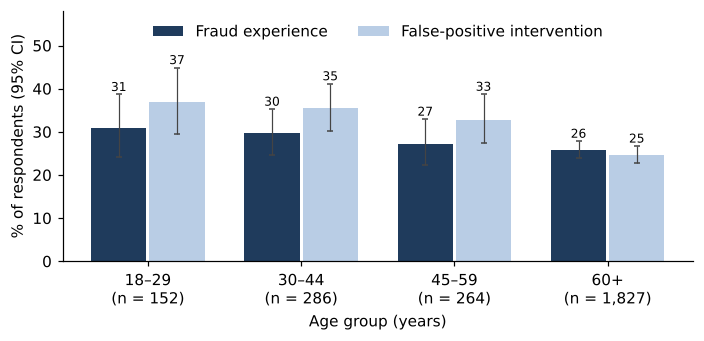

Share using each digital feature, by age group:


,Mobile banking,Online banking,P2P payments,Automated chat
AGE4,,,,
18-29,0.885,0.425,0.394,0.343
30-44,0.914,0.533,0.412,0.248
45-59,0.796,0.543,0.309,0.220
60+,0.556,0.609,0.263,0.141


,n,chi2,df,p,cramers_V
FRAUD_EXP ~ AGE4,2529.0,3.5520,3.0,0.3141,0.0375
FRAUD_EXP ~ SEX,2529.0,0.0117,1.0,0.9140,0.0021
FRAUD_EXP ~ RACE4,2529.0,26.3490,3.0,0.0000,0.1021
FRAUD_EXP ~ EDUC4,2529.0,11.6491,3.0,0.0087,0.0679
FRAUD_EXP ~ INCOME4,2529.0,25.9188,3.0,0.0000,0.1012
FALSE_POS ~ AGE4,2516.0,26.6847,3.0,0.0000,0.1030
FALSE_POS ~ SEX,2516.0,0.3448,1.0,0.5571,0.0117
FALSE_POS ~ RACE4,2516.0,45.0391,3.0,0.0000,0.1338
FALSE_POS ~ EDUC4,2516.0,7.2240,3.0,0.0651,0.0536
FALSE_POS ~ INCOME4,2516.0,12.8578,3.0,0.0050,0.0715


In [13]:
ages = ['18-29', '30-44', '45-59', '60+']
by_age = {y: rate(sub, y, 'AGE4') for y, sub in [('FRAUD_EXP', rq1), ('FALSE_POS', rq3)]}
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for j, (y, col, lab) in enumerate([('FRAUD_EXP', DARK, 'Fraud experience'), ('FALSE_POS', LIGHT, 'False-positive intervention')]):
    r = by_age[y]; p = [r[a]['p'] * 100 for a in ages]
    ax.bar(np.arange(4) + (j - .5) * .38, p, .36, color=col, label=lab, yerr=[[p[i] - r[a]['lo'] * 100 for i, a in enumerate(ages)], [r[a]['hi'] * 100 - p[i] for i, a in enumerate(ages)]], capsize=2, ecolor='#444', error_kw=dict(lw=.8))
    for i, a in enumerate(ages): ax.text(i + (j - .5) * .38, r[a]['hi'] * 100 + .8, f'{p[i]:.0f}', ha='center', fontsize=8)
ax.set_xticks(range(4), [f"{a.replace('-', '–')}\n(n = {by_age['FRAUD_EXP'][a]['n']:,})" for a in ages]); ax.set_xlabel('Age group (years)')
ax.set_ylabel('% of respondents (95% CI)'); ax.set_ylim(0, 58); ax.legend(frameon=False, ncol=2, loc='upper center')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig_age.png'), dpi=200); plt.show()

print('Share using each digital feature, by age group:')
display(pd.DataFrame({LAB[x]: d.groupby('AGE4')[x].mean().round(3) for x in F1}))
display(pd.DataFrame({f'{y} ~ {x}': chi(sub, y, x) for y, sub in [('FRAUD_EXP', rq1), ('FALSE_POS', rq3)] for x in ['AGE4', 'SEX', 'RACE4', 'EDUC4', 'INCOME4']}).T[['n', 'chi2', 'df', 'p', 'cramers_V']].astype(float).round(4))

**Insight (an anomaly worth noting).** Fraud barely changes with age (30.9% at 18–29 vs. 25.8% at 60+, p = .314), but false positives fall clearly (36.9% vs. 24.7%), and so does digital use (91.4% of 30–44-year-olds use mobile banking vs. 55.6% of those 60+). **Age confounds the digital-behavior effects**, so raw comparisons are not enough and multivariable models are required. Income and race and ethnicity are also associated with fraud (p < .001) and stay as controls.

### 5.6 Money taken among fraud victims (RQ2)

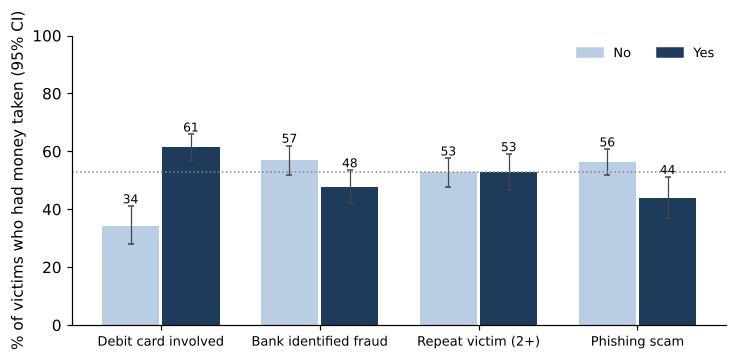

In [14]:
fig, ax = plt.subplots(figsize=(6.8, 3.2))
for i, x in enumerate(F2):
    r = rate(vic, 'FIN_LOSS', x)
    for j, (k, col) in enumerate([(0, LIGHT), (1, DARK)]):
        rr = r[k]; p = rr['p'] * 100
        ax.bar(i + (j - .5) * .38, p, .36, color=col, yerr=[[p - rr['lo'] * 100], [rr['hi'] * 100 - p]], capsize=2, ecolor='#444', error_kw=dict(lw=.8))
        ax.text(i + (j - .5) * .38, rr['hi'] * 100 + 1, f'{p:.0f}', ha='center', fontsize=8)
ax.axhline(oc['FIN_LOSS']['p'] * 100, color='#888', ls=':', lw=1)
ax.set_xticks(range(4), [LAB[x] for x in F2], fontsize=8.5); ax.set_ylabel('% of victims who had money taken (95% CI)'); ax.set_ylim(0, 100)
ax.legend([Patch(color=LIGHT), Patch(color=DARK)], ['No', 'Yes'], frameon=False, loc='upper right', ncol=2, fontsize=8.5)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig_loss.png'), dpi=200); plt.show()

**Insight.** When a debit card was involved, 61.4% of victims had money taken vs. 34.3% otherwise (the largest gap in the study). Loss was less common when the bank identified the fraud (47.8% vs. 56.9%) and for phishing victims (43.9% vs. 56.3%). Repeat victims lost money no more often. The dotted line is the rate for all victims (52.8%).

### 5.7 False positives by fraud status, and trust (RQ3)

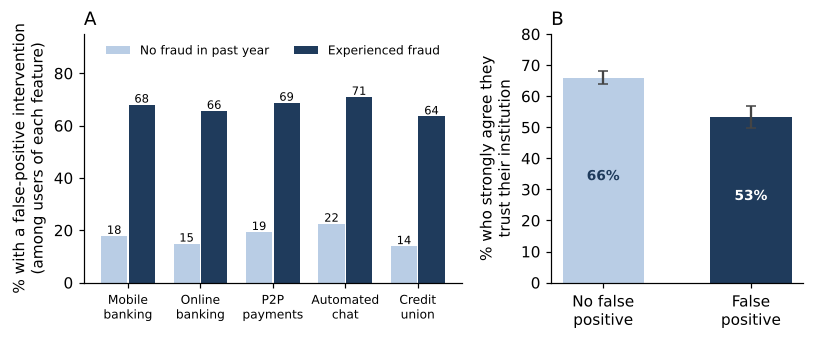

False-positive rate: victims 64.5% vs non-victims 14.2%
Trust vs false positive: {'n': 2692, 'chi2': np.float64(37.5727), 'df': 1, 'p': np.float64(0.0), 'cramers_V': np.float64(0.1181), 'min_expected': np.float64(279.1382), 'rate_if_yes': np.float64(0.5323), 'rate_if_no': np.float64(0.6602), 'crude_OR': np.float64(0.5858)}
Among non-victims only: strong trust 68.4% (no false positive) vs 61.8% (false positive)


In [15]:
fp_cross = {x: {(int(fe), int(xv)): rate(g, 'FALSE_POS') for (fe, xv), g in rq3.groupby(['FRAUD_EXP', x])} for x in F3}
t = d.dropna(subset=['TRUST_HIGH', 'FALSE_POS']); trust = rate(t, 'TRUST_HIGH', 'FALSE_POS')
fig, axs = plt.subplots(1, 2, figsize=(7.5, 3.2), gridspec_kw={'width_ratios': [1.5, 1]})
ax = axs[0]
for j, (fe, col, lab) in enumerate([(0, LIGHT, 'No fraud in past year'), (1, DARK, 'Experienced fraud')]):
    p = [fp_cross[x][(fe, 1)]['p'] * 100 for x in F3]
    ax.bar(np.arange(len(F3)) + (j - .5) * .38, p, .36, color=col, label=lab)
    for i in range(len(F3)): ax.text(i + (j - .5) * .38, p[i] + .8, f'{p[i]:.0f}', ha='center', fontsize=7.5)
ax.set_xticks(range(len(F3)), [LAB[x].replace(' ', '\n', 1) for x in F3], fontsize=8); ax.set_ylabel('% with a false-positive intervention\n(among users of each feature)')
ax.set_ylim(0, 95); ax.legend(frameon=False, fontsize=8, ncol=2, loc='upper center'); ax.set_title('A', loc='left')
ax = axs[1]; p = [trust[k]['p'] * 100 for k in [0, 1]]
ax.bar([0, 1], p, .55, color=[LIGHT, DARK], yerr=[[p[i] - trust[k]['lo'] * 100 for i, k in enumerate([0, 1])], [trust[k]['hi'] * 100 - p[i] for i, k in enumerate([0, 1])]], capsize=3, ecolor='#444')
for i in range(2): ax.text(i, p[i] / 2, f'{p[i]:.0f}%', ha='center', color='white' if i else DARK, fontsize=9, fontweight='bold')
ax.set_xticks([0, 1], ['No false\npositive', 'False\npositive']); ax.set_ylabel('% who strongly agree they\ntrust their institution'); ax.set_ylim(0, 80); ax.set_title('B', loc='left')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig_fp_trust.png'), dpi=200); plt.show()

fpf = rate(rq3, 'FALSE_POS', 'FRAUD_EXP')
print(f"False-positive rate: victims {fpf[1]['p']:.1%} vs non-victims {fpf[0]['p']:.1%}")
print('Trust vs false positive:', {k: round(v, 4) for k, v in chi(t, 'TRUST_HIGH', 'FALSE_POS').items()})
tn = rate(t[t.FRAUD_EXP == 0], 'TRUST_HIGH', 'FALSE_POS')
print(f"Among non-victims only: strong trust {tn[0]['p']:.1%} (no false positive) vs {tn[1]['p']:.1%} (false positive)")

**Insight (the strongest pattern in the data).** Fraud victims had far more false positives (64.5% vs. 14.2%), so RQ3 must control for fraud experience. Within each group, chat and P2P users still report more. Panel B shows the customer-experience cost: 66.0% of customers with no false positive strongly trust their institution, against 53.2% after one, and the gap remains among non-victims (68.4% vs. 61.8%).

### 5.8 Bivariate tests for every focal variable

In [16]:
chi_tbl = pd.DataFrame([dict(RQ=rq, variable=LAB[x], **chi(sub, y, x)) for rq, y, sub, xs in
                        [('RQ1', 'FRAUD_EXP', rq1, F1), ('RQ2', 'FIN_LOSS', vic, F2), ('RQ3', 'FALSE_POS', rq3, F3)] for x in xs])
chi_tbl = chi_tbl[['RQ', 'variable', 'n', 'rate_if_yes', 'rate_if_no', 'crude_OR', 'chi2', 'p', 'cramers_V', 'min_expected']]
chi_tbl['significant'] = np.where(chi_tbl.p < .05, 'yes', 'no')
chi_tbl.round(3)

,RQ,variable,n,rate_if_yes,rate_if_no,crude_OR,chi2,p,cramers_V,min_expected,significant
0,RQ1,Mobile banking,2512,0.290,0.223,1.422,13.172,0.000,0.072,237.470,yes
1,RQ1,Online banking,2517,0.270,0.263,1.034,0.134,0.715,0.007,278.999,no
2,RQ1,P2P payments,2529,0.322,0.244,1.475,16.594,0.000,0.081,199.644,yes
3,RQ1,Automated chat,2529,0.370,0.245,1.811,29.389,0.000,0.108,119.039,yes
4,RQ2,Debit card involved,642,0.614,0.343,3.047,41.020,0.000,0.253,96.280,yes
5,RQ2,Bank identified fraud,642,0.478,0.569,0.691,5.385,0.020,0.092,136.397,yes
6,RQ2,Repeat victim (2+),642,0.529,0.528,1.006,0.001,0.972,0.001,114.215,no
7,RQ2,Phishing scam,642,0.439,0.563,0.608,7.977,0.005,0.111,84.953,yes
8,RQ3,Mobile banking,2500,0.323,0.184,2.107,55.136,0.000,0.149,243.230,yes
9,RQ3,Online banking,2504,0.285,0.261,1.126,1.697,0.193,0.026,285.341,no


### EDA summary

| Finding | Why it matters |
|---|---|
| 7.1% unsure about fraud; predictors ≥ 98.7% complete | Complete cases are adequate for RQ1–RQ3 |
| Large weights belong to younger adults by design | Keep weights; control for age; weighted models as sensitivity check |
| False positives as common as fraud; most loss recovered | Friction deserves equal attention (RQ3) |
| Chat, P2P and mobile users have more fraud **and** more false positives | Supports H1 for RQ1 and RQ3, to be tested after controls |
| Fraud flat by age; digital use and false positives fall with age | Age is a confounder: multivariable models are required |
| Debit cards raise loss; bank detection lowers it | Supports H1 for RQ2 |
| 9 of 13 bivariate tests significant; all effects small (V ≤ .25) | Adjusted models decide the RQs |

## 6. RQ1 to RQ3: multivariable logistic regression

Each model has the focal variables plus five controls (age, sex, race and ethnicity, education, income); RQ2 also controls for mobile banking and RQ3 for fraud experience. For each model:

* **Odds ratios (OR)** with 95% CIs; *p* values adjusted for multiple testing within each RQ (Benjamini–Hochberg).
* **Likelihood-ratio (LR) test** of the focal variables together, which is the decision on each null hypothesis.
* **Diagnostics:** AIC/BIC, Nagelkerke R², Hosmer–Lemeshow calibration, variance inflation factors (VIF), Cook's distance.
* **Weighted sensitivity model** (GLM with normalized survey weights).

In [17]:
CONTROLS = "C(AGE4, Treatment('60+')) + C(SEX) + C(RACE4, Treatment('White NH')) + C(EDUC4, Treatment('HS or less')) + C(INCOME4, Treatment('Less than $30,000'))"

def nagelkerke(m, n):
    cs = 1 - np.exp(2 * (m.llnull - m.llf) / n); return cs / (1 - np.exp(2 * m.llnull / n))

def hosmer(y, p, g=10):
    q = pd.qcut(p, g, duplicates='drop'); t = pd.DataFrame({'y': y, 'p': p, 'g': q}).groupby('g', observed=True)
    O, E, n = t.y.sum(), t.p.sum(), t.y.count(); stat = (((O - E) ** 2) / (E * (1 - E / n))).sum()
    return stat, 1 - chi2.cdf(stat, len(O) - 2)

def logit_rq(y, focal, sub, extra=''):
    cols = [y] + focal + ['AGE4', 'SEX', 'RACE4', 'EDUC4', 'INCOME4', 'WEIGHT_FINAL'] + [c for c in ['FRAUD_EXP', 'MOBILE_USE'] if c in extra]
    s = sub[list(dict.fromkeys(cols))].dropna().copy()
    f_full = f"{y} ~ {' + '.join(focal)} + {CONTROLS}{extra}"
    m = smf.logit(f_full, data=s).fit(disp=0); m0 = smf.logit(f"{y} ~ {CONTROLS}{extra}", data=s).fit(disp=0)
    LR = 2 * (m.llf - m0.llf)
    mw = smf.glm(f_full, data=s, family=sm.families.Binomial(), var_weights=s.WEIGHT_FINAL / s.WEIGHT_FINAL.mean()).fit(cov_type='HC1')
    X = m.model.exog; vif = max(variance_inflation_factor(X, i) for i in range(1, X.shape[1]))
    hl, phl = hosmer(s[y].values, m.predict(s).values)
    cook = smf.glm(f_full, data=s, family=sm.families.Binomial()).fit().get_influence().cooks_distance[0]
    ci = m.conf_int(); bh = multipletests([m.pvalues[x] for x in focal], method='fdr_bh')[1]
    focal_tbl = pd.DataFrame([dict(variable=LAB[x], OR=np.exp(m.params[x]), CI_low=np.exp(ci.loc[x, 0]), CI_high=np.exp(ci.loc[x, 1]),
                                   p=m.pvalues[x], p_adjusted=bh[i], weighted_OR=np.exp(mw.params[x]), weighted_p=mw.pvalues[x]) for i, x in enumerate(focal)])
    fit = dict(n=len(s), events=int(s[y].sum()), parameters=len(m.params) - 1, LR_chi2=LR, LR_df=len(focal), LR_p=1 - chi2.cdf(LR, len(focal)),
               AIC=m.aic, AIC_without_focal=m0.aic, BIC=m.bic, Nagelkerke_R2=nagelkerke(m, len(s)), HL_p=phl,
               AUC=roc_auc_score(s[y], m.predict(s)), max_VIF=vif, max_Cooks_D=cook.max())
    return m, focal_tbl, fit

models_rq = {}
models_rq['RQ1'] = logit_rq('FRAUD_EXP', F1, rq1)
models_rq['RQ2'] = logit_rq('FIN_LOSS', F2, vic, ' + MOBILE_USE')
models_rq['RQ3'] = logit_rq('FALSE_POS', F3, rq3, ' + FRAUD_EXP')
for rq in ['RQ1', 'RQ2', 'RQ3']:
    print(f'\n========== {rq}: adjusted odds ratios for the focal variables')
    display(models_rq[rq][1].round(3))
print('\n========== Model fit and diagnostics')
pd.DataFrame({rq: models_rq[rq][2] for rq in models_rq}).astype(float).round(3)


========== RQ1: adjusted odds ratios for the focal variables


,variable,OR,CI_low,CI_high,p,p_adjusted,weighted_OR,weighted_p
0,Mobile banking,1.314,1.066,1.621,0.010,0.014,1.120,0.514
1,Online banking,1.068,0.881,1.296,0.502,0.502,0.974,0.867
2,P2P payments,1.326,1.081,1.626,0.007,0.013,1.149,0.412
3,Automated chat,1.640,1.300,2.067,0.000,0.000,1.727,0.003



========== RQ2: adjusted odds ratios for the focal variables


,variable,OR,CI_low,CI_high,p,p_adjusted,weighted_OR,weighted_p
0,Debit card involved,3.367,2.293,4.946,0.000,0.000,3.112,0.000
1,Bank identified fraud,0.520,0.366,0.738,0.000,0.001,0.719,0.241
2,Repeat victim (2+),1.097,0.774,1.555,0.603,0.603,1.064,0.817
3,Phishing scam,0.611,0.420,0.890,0.010,0.014,0.558,0.051



========== RQ3: adjusted odds ratios for the focal variables


,variable,OR,CI_low,CI_high,p,p_adjusted,weighted_OR,weighted_p
0,Mobile banking,1.765,1.381,2.256,0.000,0.000,1.670,0.009
1,Online banking,1.145,0.917,1.430,0.232,0.290,1.357,0.078
2,P2P payments,1.274,1.008,1.610,0.042,0.071,1.323,0.140
3,Automated chat,1.421,1.088,1.855,0.010,0.025,1.969,0.001
4,Credit union,0.978,0.768,1.246,0.859,0.859,1.351,0.123



========== Model fit and diagnostics


,RQ1,RQ2,RQ3
n,2500.000,635.000,2466.000
events,665.000,335.000,674.000
parameters,17.000,18.000,19.000
LR_chi2,43.974,54.494,44.209
LR_df,4.000,4.000,5.000
LR_p,0.000,0.000,0.000
AIC,2837.036,837.419,2276.497
AIC_without_focal,2873.010,883.912,2310.706
BIC,2941.869,922.037,2392.704
Nagelkerke_R2,0.054,0.156,0.338


**How to read the diagnostics.** Every LR test has *p* < .001, so **all three null hypotheses are rejected**. AIC falls when the focal variables are added (the model improves). Max VIF < 2 means no multicollinearity; Hosmer–Lemeshow *p* > .05 means adequate calibration; max Cook's D < .01 means no single respondent drives the results; events per parameter exceed 10 in every model.

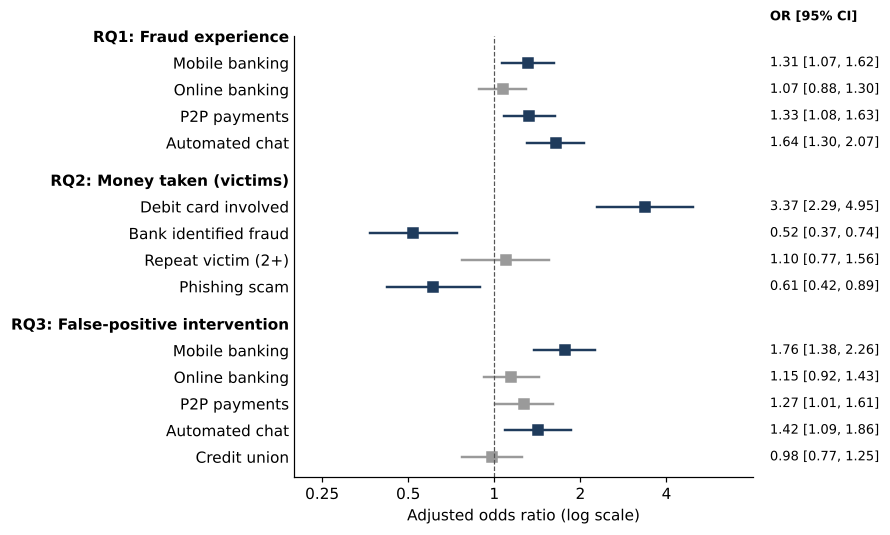

RQ3 interaction check (mobile x fraud experience): OR = 0.71, p = 0.158
RQ3 fraud-experience control: OR = 10.47


In [18]:
fig, ax = plt.subplots(figsize=(7, 5.2)); ylab, ypos = [], 0
for rq, ttl in [('RQ1', 'RQ1: Fraud experience'), ('RQ2', 'RQ2: Money taken (victims)'), ('RQ3', 'RQ3: False-positive intervention')]:
    ylab.append((ttl, ypos)); ypos -= 1
    for _, r in models_rq[rq][1].iterrows():
        col = DARK if r.p_adjusted < .05 else '#9a9a9a'
        ax.plot([r.CI_low, r.CI_high], [ypos, ypos], color=col, lw=1.6); ax.plot(r.OR, ypos, 's', color=col, ms=6)
        ax.text(9.2, ypos, f'{r.OR:.2f} [{r.CI_low:.2f}, {r.CI_high:.2f}]', va='center', fontsize=8.5)
        ylab.append((r.variable, ypos)); ypos -= 1
    ypos -= .4
ax.axvline(1, color='#555', ls='--', lw=.8); ax.set_xscale('log'); ax.set_xlim(.2, 8); ax.set_xticks([.25, .5, 1, 2, 4], ['0.25', '0.5', '1', '2', '4']); ax.minorticks_off()
ax.set_yticks([p for _, p in ylab], [t for t, _ in ylab])
for tl in ax.get_yticklabels():
    if tl.get_text().startswith('RQ'): tl.set_fontweight('bold')
ax.text(9.2, 0.6, 'OR [95% CI]', fontsize=8.5, fontweight='bold'); ax.set_xlabel('Adjusted odds ratio (log scale)'); ax.tick_params(axis='y', length=0)
fig.subplots_adjust(right=.72); plt.savefig(os.path.join(OUT, 'fig_forest.png'), dpi=200, bbox_inches='tight'); plt.show()

s3 = rq3.dropna(subset=['MOBILE_USE', 'WEB_USE', 'CREDIT_UNION'])
mi = smf.logit(f'FALSE_POS ~ MOBILE_USE*FRAUD_EXP + WEB_USE + P2P_USE + CHAT_USE + CREDIT_UNION + {CONTROLS}', data=s3).fit(disp=0)
print(f"RQ3 interaction check (mobile x fraud experience): OR = {np.exp(mi.params['MOBILE_USE:FRAUD_EXP']):.2f}, p = {mi.pvalues['MOBILE_USE:FRAUD_EXP']:.3f}")
print(f"RQ3 fraud-experience control: OR = {np.exp(models_rq['RQ3'][0].params['FRAUD_EXP']):.2f}")

Dark markers are significant after the Benjamini–Hochberg adjustment; grey markers are not.

**RQ1 (fraud exposure): H0 rejected.** Automated chat users have 1.64 times the odds of fraud; P2P (1.33) and mobile banking (1.31) users have modestly higher odds; online banking shows no association. Only the chat effect holds in the weighted model, so the mobile and P2P effects are tentative. The explained variation is small (R² = .054): fraud exposure depends mostly on things the survey does not measure.

**RQ2 (financial loss among victims): H0 rejected.** Debit-card involvement more than triples the odds that money was taken (OR 3.37). When the bank identified the fraud first, the odds of loss roughly halve (OR 0.52), and phishing victims lose money less often (OR 0.61). Repeat victimization adds nothing. This model explains the most variation of the three (R² = .156).

**RQ3 (intervention friction): H0 rejected.** Fraud experience is by far the strongest predictor (OR about 10.5), but mobile banking (OR 1.76) and automated chat (OR 1.42) still raise the odds of a false positive, and both hold when weighted. Credit unions do not differ from banks. The mobile × fraud interaction is not significant, so the mobile effect applies to victims and non-victims alike.

## 7. RQ4: machine-learning models and risk segments

**Design (leakage-safe):**
1. 14 features measured independently of the outcome (victim-only items and `FALSE_POS` are excluded because they would leak the answer). Device-use items are recoded to *very frequently vs. less*.
2. Stratified 80/20 train/test split.
3. Imputation and one-hot encoding are fitted **inside** each training fold (a scikit-learn `Pipeline`).
4. Hyperparameters tuned by stratified 5-fold cross-validation on the training set only (scored by ROC-AUC).
5. The classification threshold (max F1) and the risk-segment cut points come from out-of-fold *training* predictions.
6. The test set is used **once**.

Models: majority-class **baseline**, **L2 logistic regression**, **Random Forest**, **Gradient Boosting**. This cell takes about 3 minutes.

In [19]:
d['TYPE3'] = d.TYPE.where(d.TYPE.isin(['Bank', 'Credit Union', 'Online-only bank']))
d['COMPUTER_VF'] = np.where(d.DEVICE1.isna() | (d.DEVICE1 == 'SKIPPED ON WEB'), np.nan, (d.DEVICE1 == 'Very frequently').astype(float))
d['PHONE_VF'] = np.where(d.DEVICE2.isna() | (d.DEVICE2 == 'SKIPPED ON WEB'), np.nan, (d.DEVICE2 == 'Very frequently').astype(float))
FE_BIN = ['MOBILE_USE', 'WEB_USE', 'P2P_USE', 'CHAT_USE', 'ALERT_USE', 'COMPUTER_VF', 'PHONE_VF']
FE_CAT = ['TYPE3', 'AGE4', 'SEX', 'RACE4', 'EDUC4', 'INCOME4', 'URBAN3']

m4 = d.dropna(subset=['FRAUD_EXP']).reset_index(drop=True)
X = m4[FE_BIN + FE_CAT].copy(); y = m4.FRAUD_EXP.astype(int).values
for c in FE_CAT: X[c] = X[c].astype(object)
print('Missing values per feature (imputed inside training folds):'); print(X.isna().sum()[X.isna().sum() > 0].to_string())

Xtr, Xte, ytr, yte, itr, ite = train_test_split(X, y, np.arange(len(y)), test_size=.2, stratify=y, random_state=SEED)
print(f'\nTraining: {len(ytr)} respondents, {ytr.sum()} fraud cases | Test: {len(yte)} respondents, {yte.sum()} fraud cases')

pre = ColumnTransformer([
    ('bin', SimpleImputer(strategy='most_frequent'), FE_BIN),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', OneHotEncoder(drop='first', handle_unknown='ignore'))]), FE_CAT)])
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
models = {
    'Baseline (majority class)': (DummyClassifier(strategy='prior'), {}),
    'Logistic regression (L2)': (LogisticRegression(max_iter=2000, solver='liblinear'), {'clf__C': [.01, .03, .1, .3, 1, 3]}),
    'Random Forest': (RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=-1),
                      {'clf__max_depth': [3, 5, 8], 'clf__min_samples_leaf': [10, 25, 50], 'clf__max_features': ['sqrt', .5]}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=SEED),
                          {'clf__n_estimators': [100, 200], 'clf__learning_rate': [.03, .1], 'clf__max_depth': [2, 3], 'clf__subsample': [.8]}),
}
rng = np.random.default_rng(SEED); BOOT = [rng.integers(0, len(yte), len(yte)) for _ in range(1000)]
def boot_ci(fn, p):
    v = [fn(yte[b], p[b]) for b in BOOT if 0 < yte[b].sum() < len(b)]; return np.percentile(v, 2.5), np.percentile(v, 97.5)

R4, fitted, curves = {}, {}, {}
for name, (clf, grid) in models.items():
    gs = GridSearchCV(Pipeline([('pre', pre), ('clf', clf)]), grid or {'clf__strategy': ['prior']}, scoring='roc_auc', cv=cv, n_jobs=-1).fit(Xtr, ytr)
    best = gs.best_estimator_; fitted[name] = best
    oof = cross_val_predict(best, Xtr, ytr, cv=cv, method='predict_proba')[:, 1]
    if name.startswith('Baseline'): thr = ytr.mean()
    else:
        pr, rc, th = precision_recall_curve(ytr, oof); f = 2 * pr * rc / np.maximum(pr + rc, 1e-9); thr = th[np.argmax(f[:-1])]
    p = best.predict_proba(Xte)[:, 1]; yh = (p >= thr).astype(int); lo, hi = boot_ci(roc_auc_score, p)
    R4[name] = dict(best_params={k.replace('clf__', ''): v for k, v in gs.best_params_.items()}, cv_AUC=gs.best_score_, test_AUC=roc_auc_score(yte, p),
                    AUC_CI=f'[{lo:.3f}, {hi:.3f}]', PR_AUC=average_precision_score(yte, p), Brier=brier_score_loss(yte, p), threshold=thr,
                    accuracy=accuracy_score(yte, yh), precision=precision_score(yte, yh, zero_division=0), recall=recall_score(yte, yh), F1=f1_score(yte, yh))
    curves[name] = p
    print(f'done: {name}')
perf = pd.DataFrame(R4).T
perf

Missing values per feature (imputed inside training folds):
MOBILE_USE     17
WEB_USE        12
COMPUTER_VF     5
PHONE_VF       22
TYPE3          24

Training: 2023 respondents, 540 fraud cases | Test: 506 respondents, 135 fraud cases


done: Baseline (majority class)


done: Logistic regression (L2)


done: Random Forest


done: Gradient Boosting


,best_params,cv_AUC,test_AUC,AUC_CI,PR_AUC,Brier,threshold,accuracy,precision,recall,F1
Baseline (majority class),{'strategy': 'prior'},0.5,0.5,"[0.500, 0.500]",0.266798,0.195617,0.26693,0.266798,0.266798,1.0,0.421217
Logistic regression (L2),{'C': 3},0.620342,0.639293,"[0.576, 0.694]",0.433483,0.184153,0.234499,0.511858,0.319355,0.733333,0.444944
Random Forest,"{'max_depth': 3, 'max_features': 'sqrt', 'min_...",0.630299,0.615254,"[0.554, 0.671]",0.410719,0.190098,0.258285,0.511858,0.315789,0.711111,0.437358
Gradient Boosting,"{'learning_rate': 0.03, 'max_depth': 3, 'n_est...",0.625264,0.607048,"[0.546, 0.662]",0.36042,0.190373,0.249585,0.565217,0.332016,0.622222,0.43299


**Interpretation.** All three classifiers beat the baseline, and the lower 95% CI limit of every test ROC-AUC is above .50, so **H0 for RQ4 is rejected**. Discrimination is modest (test AUC .607 to .639; PR-AUC .360 to .433 against a chance level of .267). Accuracy is not used for selection: predicting *no fraud* for everyone would already be 73% accurate.

### 7.1 Model selection and comparison
The pre-set rule selects the model with the highest **cross-validated** AUC (training data only). A paired bootstrap compares each model's test AUC with logistic regression.

Selected model (highest CV AUC): Random Forest


  Logistic regression (L2)   test AUC minus logistic regression: +0.000  95% CI [+0.000, +0.000]


  Random Forest              test AUC minus logistic regression: -0.024  95% CI [-0.053, +0.005]


  Gradient Boosting          test AUC minus logistic regression: -0.032  95% CI [-0.056, -0.008]

Confusion matrix of the selected model on the test set (rows = actual fraud / no fraud; columns = predicted):


,Predicted fraud,Predicted no fraud
Actual fraud,96,39
Actual no fraud,208,163


Precision = 96/(96+208) = 0.316   Recall = 96/(96+39) = 0.711   Specificity = 163/(163+208) = 0.439


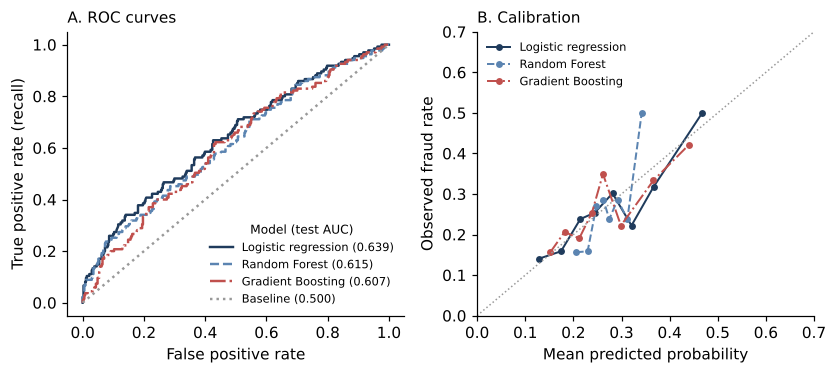

In [20]:
cands = {k: v for k, v in R4.items() if not k.startswith('Baseline')}
sel = max(cands, key=lambda k: cands[k]['cv_AUC']); best = fitted[sel]; ps = curves[sel]
print('Selected model (highest CV AUC):', sel)
lr = curves['Logistic regression (L2)']
for k in cands:
    dif = [roc_auc_score(yte[b], curves[k][b]) - roc_auc_score(yte[b], lr[b]) for b in BOOT]
    print(f'  {k:26s} test AUC minus logistic regression: {np.mean(dif):+.3f}  95% CI [{np.percentile(dif, 2.5):+.3f}, {np.percentile(dif, 97.5):+.3f}]')

cm = confusion_matrix(yte, (ps >= R4[sel]['threshold']).astype(int), labels=[1, 0])
print('\nConfusion matrix of the selected model on the test set (rows = actual fraud / no fraud; columns = predicted):')
display(pd.DataFrame(cm, index=['Actual fraud', 'Actual no fraud'], columns=['Predicted fraud', 'Predicted no fraud']))
TP, FN, FP, TN = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
print(f'Precision = {TP}/({TP}+{FP}) = {TP/(TP+FP):.3f}   Recall = {TP}/({TP}+{FN}) = {TP/(TP+FN):.3f}   Specificity = {TN}/({TN}+{FP}) = {TN/(TN+FP):.3f}')

fig, axs = plt.subplots(1, 2, figsize=(7.6, 3.5))
sty = {'Logistic regression (L2)': (DARK, '-'), 'Random Forest': (MID, '--'), 'Gradient Boosting': (ACC, '-.'), 'Baseline (majority class)': ('#999', ':')}
for k, (c, ls) in sty.items():
    fpr, tpr, _ = roc_curve(yte, curves[k]); axs[0].plot(fpr, tpr, color=c, ls=ls, lw=1.6, label=f"{k.replace(' (majority class)', '').replace(' (L2)', '')} ({R4[k]['test_AUC']:.3f})")
    if not k.startswith('Baseline'):
        fp_, mp_ = calibration_curve(yte, curves[k], n_bins=8, strategy='quantile'); axs[1].plot(mp_, fp_, marker='o', ms=3.5, color=c, ls=ls, lw=1.3, label=k.replace(' (L2)', ''))
axs[0].set_xlabel('False positive rate'); axs[0].set_ylabel('True positive rate (recall)'); axs[0].legend(frameon=False, fontsize=7.5, title='Model (test AUC)', title_fontsize=8, loc='lower right'); axs[0].set_title('A. ROC curves', fontsize=10, loc='left')
axs[1].plot([0, .7], [0, .7], color='#999', ls=':', lw=1); axs[1].set_xlim(0, .7); axs[1].set_ylim(0, .7)
axs[1].set_xlabel('Mean predicted probability'); axs[1].set_ylabel('Observed fraud rate'); axs[1].legend(frameon=False, fontsize=7.5); axs[1].set_title('B. Calibration', fontsize=10, loc='left')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig_roc.png'), dpi=200); plt.show()

**Interpretation.** Random Forest is selected by the pre-set rule (CV AUC .630). On the test set, logistic regression scored slightly higher (.639), but the difference is not significant (the CI includes zero), whereas Gradient Boosting is significantly worse. This matches the literature: flexible learners add little on small, low-dimensional survey data. The calibration curves lie close to the diagonal, so the predicted probabilities can be used as risk scores.

### 7.2 Risk segments, importance and fairness
Segment cut points are the tertiles of the selected model's out-of-fold *training* predictions, then applied to the test set.

,n,fraud_rate,lift,aged_60_plus,mobile,p2p,chat,false_pos_rate
SEG,,,,,,,,
Lower,161,0.186,0.698,0.839,0.381,0.124,0.006,0.169
Moderate,159,0.258,0.967,0.755,0.772,0.340,0.101,0.239
Higher,186,0.344,1.290,0.602,0.768,0.478,0.409,0.392


Higher / lower segment fraud-rate ratio: 1.85  (target: 1.5 or more)


,n,test_AUC,fraud_rate,share_in_higher_segment
group,,,,
60+,367,0.571,0.243,0.305
under 60,139,0.692,0.331,0.532
Female,287,0.605,0.247,0.376
Male,219,0.629,0.292,0.356


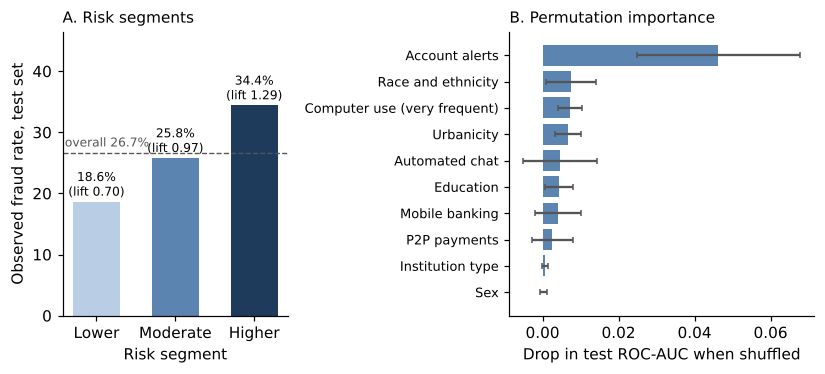

In [21]:
oof = cross_val_predict(best, Xtr, ytr, cv=cv, method='predict_proba')[:, 1]
c1_, c2_ = np.quantile(oof, [1 / 3, 2 / 3])
seg = np.where(ps < c1_, 'Lower', np.where(ps < c2_, 'Moderate', 'Higher'))
te = m4.iloc[ite].copy(); te['SEG'] = seg; te['y'] = yte; base = yte.mean()
prof = te.groupby('SEG').agg(n=('y', 'size'), fraud_rate=('y', 'mean'), aged_60_plus=('AGE4', lambda s: (s == '60+').mean()),
                             mobile=('MOBILE_USE', 'mean'), p2p=('P2P_USE', 'mean'), chat=('CHAT_USE', 'mean'), false_pos_rate=('FALSE_POS', 'mean')).loc[['Lower', 'Moderate', 'Higher']]
prof.insert(2, 'lift', prof.fraud_rate / base)
display(prof.round(3))
print(f"Higher / lower segment fraud-rate ratio: {prof.loc['Higher', 'fraud_rate'] / prof.loc['Lower', 'fraud_rate']:.2f}  (target: 1.5 or more)")

pi = permutation_importance(best, Xte, yte, scoring='roc_auc', n_repeats=30, random_state=SEED)
imp = pd.DataFrame({'feature': X.columns, 'importance': pi.importances_mean, 'sd': pi.importances_std}).sort_values('importance', ascending=False)

fair = []
for label, mask in [('60+', te.AGE4 == '60+'), ('under 60', te.AGE4 != '60+'), ('Female', te.SEX == 'Female'), ('Male', te.SEX == 'Male')]:
    mk = mask.values; fair.append(dict(group=label, n=mk.sum(), test_AUC=roc_auc_score(yte[mk], ps[mk]), fraud_rate=yte[mk].mean(), share_in_higher_segment=(seg[mk] == 'Higher').mean()))
display(pd.DataFrame(fair).set_index('group').round(3))

FL = {'MOBILE_USE': 'Mobile banking', 'WEB_USE': 'Online banking', 'P2P_USE': 'P2P payments', 'CHAT_USE': 'Automated chat', 'ALERT_USE': 'Account alerts',
      'COMPUTER_VF': 'Computer use (very frequent)', 'PHONE_VF': 'Smartphone use (very frequent)', 'TYPE3': 'Institution type', 'AGE4': 'Age group', 'SEX': 'Sex',
      'RACE4': 'Race and ethnicity', 'EDUC4': 'Education', 'INCOME4': 'Household income', 'URBAN3': 'Urbanicity'}
fig, axs = plt.subplots(1, 2, figsize=(7.6, 3.5), gridspec_kw={'width_ratios': [1, 1.35]})
ss_ = ['Lower', 'Moderate', 'Higher']; rt = [prof.loc[s_, 'fraud_rate'] * 100 for s_ in ss_]
axs[0].bar(ss_, rt, color=[LIGHT, MID, DARK], width=.6); axs[0].axhline(base * 100, color='#555', ls='--', lw=.9)
axs[0].text(-.4, base * 100 + 1, f'overall {base * 100:.1f}%', ha='left', fontsize=8, color='#555')
for i, s_ in enumerate(ss_): axs[0].text(i, rt[i] + 1, f"{rt[i]:.1f}%\n(lift {prof.loc[s_, 'lift']:.2f})", ha='center', fontsize=8)
axs[0].set_ylim(0, max(rt) * 1.35); axs[0].set_ylabel('Observed fraud rate, test set'); axs[0].set_xlabel('Risk segment'); axs[0].set_title('A. Risk segments', fontsize=10, loc='left')
top = imp.head(10).iloc[::-1]
axs[1].barh([FL[a] for a in top.feature], top.importance, xerr=top.sd, color=MID, ecolor='#555', capsize=2)
axs[1].set_xlabel('Drop in test ROC-AUC when shuffled'); axs[1].set_title('B. Permutation importance', fontsize=10, loc='left'); axs[1].tick_params(axis='y', labelsize=8.5)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig_segments.png'), dpi=200); plt.show()

**Interpretation.**
* **Segments work:** the higher-risk segment has 34.4% fraud vs. 18.6% in the lower-risk segment, a ratio of 1.85, which meets the pre-set target of 1.5.
* **Profile:** the higher-risk segment is younger, uses chat and P2P far more, and also has more than twice the false-positive rate, so the customers most exposed to fraud are also the most exposed to friction.
* **Importance:** account alerts rank first. Because customers may switch alerts on *after* a fraud, this feature may partly reflect the outcome (reverse causation); step 8 checks this.
* **Fairness:** the model separates risk less well for adults aged 60+ (AUC .57) than for younger adults (.69). This will be reviewed in the final report.

## 8. Sensitivity check: RQ4 without account alerts
Same design as step 7, with `ALERT_USE` removed (about 1 minute).

In [22]:
print('Fraud rate by account-alert use:', m4.groupby('ALERT_USE').FRAUD_EXP.mean().round(3).to_dict())
BIN2 = [c for c in FE_BIN if c != 'ALERT_USE']
X2 = m4[BIN2 + FE_CAT].copy()
for c in FE_CAT: X2[c] = X2[c].astype(object)
Xtr2, Xte2, ytr2, yte2 = train_test_split(X2, y, test_size=.2, stratify=y, random_state=SEED)
pre2 = ColumnTransformer([('b', SimpleImputer(strategy='most_frequent'), BIN2),
                          ('c', Pipeline([('i', SimpleImputer(strategy='most_frequent')), ('o', OneHotEncoder(drop='first', handle_unknown='ignore'))]), FE_CAT)])
sens = {}
for name in ['Logistic regression (L2)', 'Random Forest']:
    clf, grid = models[name]
    gs = GridSearchCV(Pipeline([('pre', pre2), ('clf', clf)]), grid, scoring='roc_auc', cv=cv, n_jobs=-1).fit(Xtr2, ytr2)
    sens[name] = dict(cv_AUC_without_alerts=gs.best_score_, test_AUC_without_alerts=roc_auc_score(yte2, gs.predict_proba(Xte2)[:, 1]),
                      test_AUC_with_alerts=R4[name]['test_AUC'])
pd.DataFrame(sens).T.round(3)

Fraud rate by account-alert use: {0: 0.187, 1: 0.317}


,cv_AUC_without_alerts,test_AUC_without_alerts,test_AUC_with_alerts
Logistic regression (L2),0.591,0.626,0.639
Random Forest,0.605,0.583,0.615


**Interpretation.** Account-alert users report more fraud (31.7% vs. 18.7%). Without alerts, test AUC falls to .626 for logistic regression and .583 for Random Forest. The final model will be chosen with and without this feature, and the decision will be discussed with the mentor.

## 9. Mentor feedback on RQ4

The mentor asked three questions after the interim review:
1. **AUC is low: are more input variables needed?** (section 9.1)
2. **Why are precision and recall low?** (section 9.2)
3. **Explain false positives and false negatives with real examples.** (section 9.3)

Sections 9.1 to 9.3 use the same 80/20 split and the same leakage-safe design as step 7, so the results are directly comparable.

### 9.1 Do more input variables improve the AUC?
The survey has 284 columns, and step 7 used only 14 features. We screened every item against three rules: it must be **asked of every respondent**, it must **not be about fraud**, and it must **not plausibly be a reaction to fraud**. Excluded: fraud-alert services, trust in the institution, preferred fraud-contact channel, and health or disability items (sensitive). The candidates form three groups, added one at a time:

| Set | What is added | Examples |
|---|---|---|
| S0 | Original 14 features (step 7) | Digital use, alerts, devices, age, income |
| S1 | Finer demographics and household | 7 age bands, 9 income bands, marital status, employment, household size, housing, region |
| S2 | Banking relationship and channels | Years with the bank, overdraft history, ATM and branch use, phone contact, bill pay, accounts and loans held |
| S3 | Financial situation, life events, support | Financial well-being score, credit record, life events (moved, retired, widowed), caregiver, power of attorney, trusted contact |
| S4 | **Strict:** S3 minus anything that could be a *reaction* to fraud | Drops alerts, recent calls to the bank, needing online-banking help, credit record, well-being score, reduced income |

This cell takes about 5 minutes.

In [23]:
SPECIAL2 = ['SKIPPED ON WEB', "DON'T KNOW", 'REFUSED', "I'm not sure", 'Unknown', "I don't know", 'I don’t know', 'I don’t know.', "Don't know", 'Prefer not to say', '98', '']
def clean(s):
    s = s.astype(str).str.strip(); return s.where(~s.isin(SPECIAL2 + ['nan']))
YNc = lambda c: clean(d[c]).map({'Yes': 1.0, 'No': 0.0})
# Group A: finer demographics and household
for c in ['AGE7', 'INCOME9', 'EDUC5', 'MARITAL', 'EMPLOY', 'HHSIZE', 'HOUSING', 'REGION4', 'PHONESERVICE']: d[c + '_c'] = clean(d[c])
for c in ['CHILDREN', 'LANGOTHR', 'VETERAN']: d[c + '_b'] = YNc(c)
d['METRO_b'] = (d.METRO == 'Metro Area').astype(float); d['INTERNET_b'] = (d.INTERNET == 'Internet Household').astype(float)
A_CAT = ['AGE7_c', 'INCOME9_c', 'EDUC5_c', 'MARITAL_c', 'EMPLOY_c', 'HHSIZE_c', 'HOUSING_c', 'REGION4_c', 'PHONESERVICE_c']
A_BIN = ['CHILDREN_b', 'LANGOTHR_b', 'VETERAN_b', 'METRO_b', 'INTERNET_b']
# Group B: banking relationship, products and channels
d['LENGTH_c'] = clean(d.LENGTH); d['BIGBANK_b'] = YNc('BIGBANK'); d['OVER_c'] = clean(d.OVER); d['DEVICE3_c'] = clean(d.DEVICE3)
for c in ['ATM', 'TRAIN1', 'BRANCH', 'WIN']: d[c + '_b'] = YNc(c)
d['PHONE_REP_b'] = YNc('PHONE1_1'); d['PHONE_AUTO_b'] = YNc('PHONE1_2')
for i in [1, 2, 3, 4]: d[f'ACC2_{i}_b'] = YNc(f'ACC2_{i}')       # paper statements, larger font, ATM video teller, passenger-side ATM
for i in [3, 4, 6]: d[f'FEAT1_{i}_b'] = YNc(f'FEAT1_{i}')       # bill-pay reminders, online/automatic bill pay, overdraft protection
for i in range(1, 7): d[f'ASSET_{i}_b'] = YNc(f'ASSETS_{i}')
for i in range(1, 6): d[f'DEBT_{i}_b'] = YNc(f'DEBT2_{i}')
d['ASSETS_n'] = pd.to_numeric(d.ASSETS_COUNT, errors='coerce'); d['DEBT_n'] = pd.to_numeric(d.DEBT2_COUNT, errors='coerce')
B_CAT = ['LENGTH_c', 'OVER_c', 'DEVICE3_c']
B_BIN = ['BIGBANK_b', 'ATM_b', 'TRAIN1_b', 'BRANCH_b', 'WIN_b', 'PHONE_REP_b', 'PHONE_AUTO_b', 'ACC2_1_b', 'ACC2_2_b', 'ACC2_3_b', 'ACC2_4_b',
         'FEAT1_3_b', 'FEAT1_4_b', 'FEAT1_6_b'] + [f'ASSET_{i}_b' for i in range(1, 7)] + [f'DEBT_{i}_b' for i in range(1, 6)]
B_NUM = ['ASSETS_n', 'DEBT_n']
# Group C: financial situation, life events (non-health), support arrangements
d['FWB_n'] = pd.to_numeric(d.FWB, errors='coerce'); d['SKILL_c'] = clean(d.SKILL); d['CREDREC_c'] = clean(d.CREDREC)
for c in ['HELP', 'CG', 'CONT']: d[c + '_b'] = YNc(c)
d['POA1_b'] = YNc('POA1'); d['CONT3_b'] = YNc('CONT3')
SH = {1: 'widowed', 2: 'moved', 3: 'disaster_loss', 8: 'became_caregiver', 9: 'fully_retired', 10: 'part_retired', 11: 'reduced_hours', 12: 'reduced_income'}
for i, nm in SH.items(): d[f'SHOCK_{nm}_b'] = YNc(f'SHOCK1_{i}')
C_CAT = ['SKILL_c', 'CREDREC_c']; C_BIN = ['HELP_b', 'CG_b', 'CONT_b', 'POA1_b', 'CONT3_b'] + [f'SHOCK_{nm}_b' for nm in SH.values()]; C_NUM = ['FWB_n']

SETS = {'S0': (FE_BIN, FE_CAT, []), 'S1': (FE_BIN + A_BIN, FE_CAT + A_CAT, []), 'S2': (FE_BIN + A_BIN + B_BIN, FE_CAT + A_CAT + B_CAT, B_NUM),
        'S3': (FE_BIN + A_BIN + B_BIN + C_BIN, FE_CAT + A_CAT + B_CAT + C_CAT, B_NUM + C_NUM)}
SUSPECT = ['ALERT_USE', 'PHONE_REP_b', 'PHONE_AUTO_b', 'TRAIN1_b', 'CREDREC_c', 'FWB_n', 'SHOCK_reduced_income_b']
SETS['S4'] = tuple([x for x in part if x not in SUSPECT] for part in SETS['S3'])

from sklearn.preprocessing import StandardScaler
def make_pre(BIN, CAT, NUM):
    t = [('bin', SimpleImputer(strategy='most_frequent'), BIN),
         ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', OneHotEncoder(drop='first', handle_unknown='ignore'))]), CAT)]
    if NUM: t.append(('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM))
    return ColumnTransformer(t)
MODELS9 = {
    'Logistic (L2)': (LogisticRegression(max_iter=4000, solver='liblinear'), {'clf__C': [.003, .01, .03, .1, .3, 1]}),
    'Logistic (L1, selects features)': (LogisticRegression(max_iter=4000, solver='liblinear', penalty='l1'), {'clf__C': [.01, .03, .1, .3, 1]}),
    'Random Forest': (RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=-1), {'clf__max_depth': [3, 5, 8], 'clf__min_samples_leaf': [10, 25, 50], 'clf__max_features': ['sqrt', .3]}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=SEED), {'clf__n_estimators': [100, 200], 'clf__learning_rate': [.03, .1], 'clf__max_depth': [2, 3], 'clf__subsample': [.8]}),
}
m9 = d.dropna(subset=['FRAUD_EXP']).reset_index(drop=True)          # same rows and order as step 7, so the same split indices apply
rows9, preds9, fitted9 = [], {}, {}
for sname, (BIN, CAT, NUM) in SETS.items():
    X9 = m9[BIN + CAT + NUM].copy()
    for c in CAT: X9[c] = X9[c].astype(object)
    Xtr9, Xte9 = X9.iloc[itr], X9.iloc[ite]
    npar = make_pre(BIN, CAT, NUM).fit_transform(Xtr9).shape[1]
    for mname, (clf, grid) in MODELS9.items():
        gs = GridSearchCV(Pipeline([('pre', make_pre(BIN, CAT, NUM)), ('clf', clf)]), grid, scoring='roc_auc', cv=cv, n_jobs=-1).fit(Xtr9, ytr)
        p9 = gs.predict_proba(Xte9)[:, 1]; preds9[(sname, mname)] = p9; fitted9[(sname, mname)] = gs.best_estimator_
        lo, hi = boot_ci(roc_auc_score, p9)
        rows9.append(dict(set=sname, model=mname, features=len(BIN + CAT + NUM), parameters=npar, cv_AUC=gs.best_score_, test_AUC=roc_auc_score(yte, p9),
                          AUC_CI=f'[{lo:.3f}, {hi:.3f}]', PR_AUC=average_precision_score(yte, p9), train_AUC=roc_auc_score(ytr, gs.predict_proba(Xtr9)[:, 1])))
    print('done', sname)
res9 = pd.DataFrame(rows9)
for i, r in res9.iterrows():
    if r.set != 'S0':
        a, b = preds9[('S0', r.model)], preds9[(r.set, r.model)]
        dif = [roc_auc_score(yte[k], b[k]) - roc_auc_score(yte[k], a[k]) for k in BOOT]
        res9.loc[i, 'gain_vs_S0'] = f'{np.mean(dif):+.3f} [{np.percentile(dif, 2.5):+.3f}, {np.percentile(dif, 97.5):+.3f}]'
res9.round(3)

done S0


done S1


done S2


done S3


done S4


,set,model,features,parameters,cv_AUC,test_AUC,AUC_CI,PR_AUC,train_AUC,gain_vs_S0
0,S0,Logistic (L2),14,24,0.620,0.638,"[0.575, 0.692]",0.432,0.652,NaN
1,S0,"Logistic (L1, selects features)",14,24,0.625,0.617,"[0.555, 0.673]",0.413,0.641,NaN
2,S0,Random Forest,14,24,0.630,0.615,"[0.554, 0.671]",0.411,0.660,NaN
3,S0,Gradient Boosting,14,24,0.625,0.607,"[0.546, 0.662]",0.360,0.708,NaN
4,S1,Logistic (L2),28,71,0.626,0.638,"[0.576, 0.693]",0.421,0.677,"-0.001 [-0.037, +0.036]"
5,S1,"Logistic (L1, selects features)",28,71,0.628,0.634,"[0.574, 0.687]",0.423,0.658,"+0.016 [-0.013, +0.045]"
6,S1,Random Forest,28,71,0.647,0.621,"[0.561, 0.675]",0.401,0.754,"+0.005 [-0.023, +0.033]"
7,S1,Gradient Boosting,28,71,0.644,0.624,"[0.566, 0.679]",0.399,0.746,"+0.017 [-0.014, +0.049]"
8,S2,Logistic (L2),58,108,0.671,0.701,"[0.644, 0.753]",0.491,0.728,"+0.063 [+0.021, +0.112]"
9,S2,"Logistic (L1, selects features)",58,108,0.669,0.721,"[0.664, 0.772]",0.508,0.710,"+0.104 [+0.055, +0.154]"


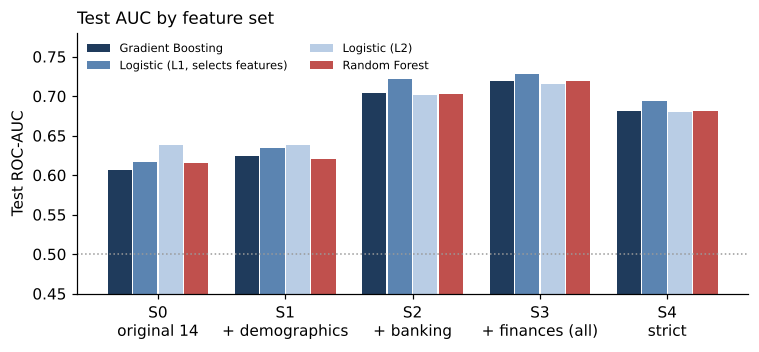

Strict L1 model keeps 33 of 120 parameters. Strongest (+ raises risk, - lowers):


,coefficient
cat__OVER_c_I have never had an overdraft on my account.,-0.721
cat__OVER_c_Never,-0.552
cat__HOUSING_c_Owned or being bought by you or someone in your household,-0.324
bin__ATM_b,0.204
cat__EMPLOY_c_Not working – retired,-0.193
bin__CHAT_USE,0.174
bin__FEAT1_3_b,0.165
cat__MARITAL_c_Never married,-0.143
bin__BRANCH_b,0.132
"cat__INCOME9_c_$100,000 to under $150,000",-0.125


In [24]:
piv = res9.pivot(index='set', columns='model', values='test_AUC')
fig, ax = plt.subplots(figsize=(7, 3.3)); xs = np.arange(len(piv)); cols = [DARK, MID, LIGHT, ACC]
for j, mname in enumerate(piv.columns):
    ax.bar(xs + (j - 1.5) * .2, piv[mname], .19, color=cols[j], label=mname)
ax.axhline(.5, color='#999', ls=':', lw=1); ax.set_ylim(.45, .78); ax.set_xticks(xs, ['S0\noriginal 14', 'S1\n+ demographics', 'S2\n+ banking', 'S3\n+ finances (all)', 'S4\nstrict'])
ax.set_ylabel('Test ROC-AUC'); ax.legend(frameon=False, fontsize=7.5, ncol=2, loc='upper left'); ax.set_title('Test AUC by feature set', loc='left', fontsize=11)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig_feature_sets.png'), dpi=200); plt.show()

l1 = fitted9[('S4', 'Logistic (L1, selects features)')]
coef = pd.Series(l1.named_steps['clf'].coef_[0], index=l1.named_steps['pre'].get_feature_names_out())
coef = coef[coef != 0]
print(f'Strict L1 model keeps {len(coef)} of {len(l1.named_steps["pre"].get_feature_names_out())} parameters. Strongest (+ raises risk, - lowers):')
coef.reindex(coef.abs().sort_values(ascending=False).index).head(15).round(3).to_frame('coefficient')

**Interpretation.**
* **Finer demographics alone (S1) do not help:** the gain is about +0.01 and not significant. More detail on age or income adds little beyond what the 14 features already capture.
* **Banking-relationship variables (S2) are what help:** test AUC rises to about **.70**, a gain of +0.06 to +0.10 that is statistically significant (the CI excludes zero). Adding financial situation and support (S3) lifts it to about **.72**.
* **The gain is not leakage.** The strict set S4, which drops everything that could be a reaction to fraud, still reaches **.68–.69** (a gain of +0.04 to +0.08, significant for three of the four models).
* **What the strict model uses:** a clean overdraft history (never charged, or never overdrawn) and owning a home are linked to *lower* risk; ATM and branch use, automated chat, bill-pay reminders, being a caregiver, and having more loans are linked to *higher* risk. This fits the RQ1 picture: more channels and more transactions mean more exposure, while financial stability is protective.
* **Caveat:** more parameters need more data. By Riley et al. (2019), about 120 candidate parameters would need roughly 9,900 respondents, against 2,023 for training. Regularization (L1/L2) and the single held-out test reduce the risk, and the training and test AUCs are close for the logistic models (no sign of overfitting), but the final report should prefer the **sparse L1 logistic model**, which keeps only about 33 parameters.

In [25]:
def topk(p, frac):
    t = np.quantile(p, 1 - frac); yh = (p >= t).astype(int); TP = int(((yh == 1) & (yte == 1)).sum())
    return dict(flagged=int(yh.sum()), fraud_found=TP, precision=TP / yh.sum(), recall=TP / yte.sum(), lift=TP / yh.sum() / yte.mean())
cmp = {'S0 Random Forest (interim model)': preds9[('S0', 'Random Forest')], 'S4 strict, L1 logistic': preds9[('S4', 'Logistic (L1, selects features)')],
       'S3 all, L1 logistic': preds9[('S3', 'Logistic (L1, selects features)')]}
pd.concat({k: pd.DataFrame({f'top {int(f * 100)}%': topk(v, f) for f in [.1, .2, .33]}).T for k, v in cmp.items()}).round(3)

flagged  fraud_found  precision  recall   lift
S0 Random Forest (interim model) top 10%     51.0         26.0      0.510   0.193  1.911
                                 top 20%    102.0         43.0      0.422   0.319  1.580
                                 top 33%    167.0         61.0      0.365   0.452  1.369
S4 strict, L1 logistic           top 10%     51.0         30.0      0.588   0.222  2.205
                                 top 20%    102.0         48.0      0.471   0.356  1.764
                                 top 33%    167.0         75.0      0.449   0.556  1.683
S3 all, L1 logistic              top 10%     51.0         31.0      0.608   0.230  2.278
                                 top 20%    102.0         53.0      0.520   0.393  1.948
                                 top 33%    167.0         77.0      0.461   0.570  1.728

**What this means in practice.** If the bank flags the riskiest 10% of customers, precision rises from **.51** (interim model) to **.59** (strict model) and **.61** (all variables); for the riskiest third, the share of all fraud victims found rises from **45%** to **56–57%**. Better inputs improve precision and recall together, which a different threshold alone cannot do.

### 9.2 Why are precision and recall low?
Using the interim model (Random Forest, original 14 features) at its chosen threshold of 0.258: **precision = .316** and **recall = .711**. Three reasons:

1. **Fraud is the minority class (26.7%).** A random guess has precision .267, so .316 is above chance but not by much. Precision is always judged against the base rate.
2. **The threshold was set to maximize F1, which favors recall.** It flags 60% of test respondents, so it finds 71% of victims but includes many non-victims. A stricter threshold raises precision and lowers recall (the trade-off below).
3. **The inputs barely separate the two groups.** Victims and non-victims have heavily overlapping risk scores (second chart), because many people share the same profile and only some of them happened to be targeted. This is the real limit, which is why better inputs (9.1) help more than any threshold.

,rule,threshold,flagged,flagged_pct,TP,FP,FN,TN,precision,recall,specificity,F1,lift
0,Chosen (max F1 on training),0.258,304,0.601,96,208,39,163,0.316,0.711,0.439,0.437,1.184
1,Flag top 10%,0.328,51,0.101,26,25,109,346,0.510,0.193,0.933,0.280,1.911
2,Flag top 20%,0.309,102,0.202,43,59,92,312,0.422,0.319,0.841,0.363,1.580
3,Flag top 33%,0.290,169,0.334,61,108,74,263,0.361,0.452,0.709,0.401,1.353
4,Flag top 50%,0.268,253,0.500,80,173,55,198,0.316,0.593,0.534,0.412,1.185


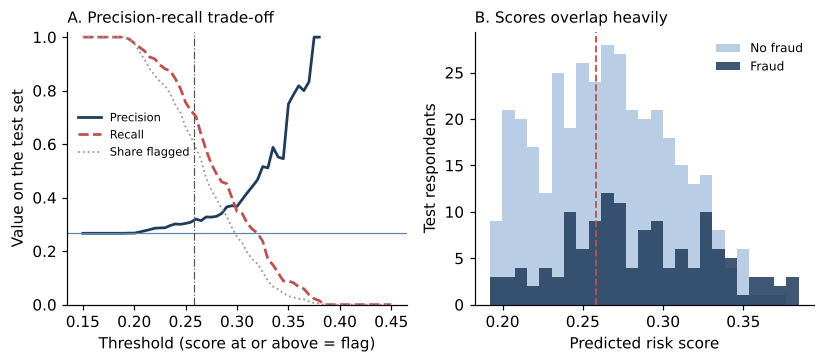

In [26]:
THR = R4[sel]['threshold']
def at(t):
    yh = (ps >= t).astype(int); TP = int(((yh == 1) & (yte == 1)).sum()); FP = int(((yh == 1) & (yte == 0)).sum())
    FN = int(((yh == 0) & (yte == 1)).sum()); TN = int(((yh == 0) & (yte == 0)).sum()); prec = TP / (TP + FP) if TP + FP else np.nan; rec = TP / (TP + FN)
    return dict(threshold=t, flagged=TP + FP, flagged_pct=(TP + FP) / len(yte), TP=TP, FP=FP, FN=FN, TN=TN, precision=prec, recall=rec,
                specificity=TN / (TN + FP), F1=2 * prec * rec / (prec + rec) if TP else 0, lift=prec / yte.mean() if TP + FP else np.nan)
qs = np.quantile(ps, [.9, .8, .667, .5])
sweep = pd.DataFrame([dict(rule='Chosen (max F1 on training)', **at(THR))] + [dict(rule=f'Flag top {k}', **at(float(t))) for k, t in zip(['10%', '20%', '33%', '50%'], qs)])
display(sweep.round(3))

fig, axs = plt.subplots(1, 2, figsize=(7.6, 3.4))
ts = np.linspace(.15, .45, 61); P = [at(t) for t in ts]
axs[0].plot(ts, [r['precision'] for r in P], color=DARK, lw=1.8, label='Precision'); axs[0].plot(ts, [r['recall'] for r in P], color=ACC, lw=1.8, ls='--', label='Recall')
axs[0].plot(ts, [r['flagged_pct'] for r in P], color='#999', lw=1.2, ls=':', label='Share flagged'); axs[0].axhline(yte.mean(), color=MID, lw=.8)
axs[0].axvline(THR, color='#555', lw=.8, ls='-.'); axs[0].set_xlabel('Threshold (score at or above = flag)'); axs[0].set_ylabel('Value on the test set'); axs[0].set_ylim(0, 1.02)
axs[0].legend(frameon=False, fontsize=7.5, loc='center left', bbox_to_anchor=(0.0, 0.62)); axs[0].set_title('A. Precision-recall trade-off', fontsize=10, loc='left')
bins = np.linspace(ps.min(), ps.max(), 26)
axs[1].hist(ps[yte == 0], bins=bins, color=LIGHT, label='No fraud'); axs[1].hist(ps[yte == 1], bins=bins, color=DARK, alpha=.85, label='Fraud')
axs[1].axvline(THR, color=ACC, ls='--', lw=1.2); axs[1].set_xlabel('Predicted risk score'); axs[1].set_ylabel('Test respondents'); axs[1].legend(frameon=False, fontsize=8)
axs[1].set_title('B. Scores overlap heavily', fontsize=10, loc='left')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'fig_pr_tradeoff.png'), dpi=200); plt.show()

**Reading the trade-off.** Flagging only the top 10% gives precision **.51** (about 1 in 2 flagged customers is a real victim, 1.9 times the base rate) but recall **.19**. Flagging 60% (the chosen threshold) finds **71%** of victims at precision **.32**. The right threshold is a business choice. For a cheap action such as a scam-awareness message, high recall is better; for a costly action such as a manual review, high precision is better.

### 9.3 False positives and false negatives, with real examples

| | Model says **at risk** | Model says **not at risk** |
|---|---|---|
| **Actually had fraud** | **True positive (TP):** victim correctly flagged | **False negative (FN):** victim *missed* |
| **No fraud** | **False positive (FP):** non-victim wrongly flagged | **True negative (TN):** correctly not flagged |

*Note on terms:* a **model false positive** (a prediction error) is different from the survey variable **FALSE_POS** (a bank fraud intervention that turned out not to be fraud, the RQ3 outcome).

In [27]:
te['score'] = ps; te['pred'] = (ps >= THR).astype(int); te['y'] = yte
te['group'] = np.select([(te.y == 1) & (te.pred == 1), (te.y == 0) & (te.pred == 1), (te.y == 1) & (te.pred == 0), (te.y == 0) & (te.pred == 0)],
                        ['TP: fraud, flagged', 'FP: no fraud, flagged', 'FN: fraud, missed', 'TN: no fraud, not flagged'], default='')
order = ['TP: fraud, flagged', 'FN: fraud, missed', 'FP: no fraud, flagged', 'TN: no fraud, not flagged']
prof9 = te.groupby('group').agg(n=('y', 'size'), mean_score=('score', 'mean'), aged_60_plus=('AGE4', lambda s: (s == '60+').mean()),
    mobile=('MOBILE_USE', 'mean'), p2p=('P2P_USE', 'mean'), chat=('CHAT_USE', 'mean'), alerts=('ALERT_USE', 'mean'),
    income_100k_plus=('INCOME4', lambda s: (s == '$100,000 or more').mean())).loc[order]
print('Average profile of each group (shares, test set):'); display(prof9.round(3))

show = ['group', 'CASEID', 'AGE4', 'SEX', 'INCOME4', 'MOBILE_USE', 'P2P_USE', 'CHAT_USE', 'ALERT_USE', 'TYPE3', 'score', 'FRAUD1']
ex = pd.concat([te[te.group == g].sort_values('score', ascending=asc).head(3) for g, asc in
                [('TP: fraud, flagged', False), ('FP: no fraud, flagged', False), ('FN: fraud, missed', True), ('TN: no fraud, not flagged', True)]])[show]
print('Real test-set respondents: the 3 highest-scoring TPs and FPs, and the 3 lowest-scoring FNs and TNs:'); ex.round(3)

Average profile of each group (shares, test set):


,n,mean_score,aged_60_plus,mobile,p2p,chat,alerts,income_100k_plus
group,,,,,,,,
"TP: fraud, flagged",96,0.306,0.583,0.800,0.510,0.344,0.906,0.167
"FN: fraud, missed",39,0.232,0.846,0.474,0.128,0.000,0.282,0.128
"FP: no fraud, flagged",208,0.295,0.692,0.792,0.418,0.269,0.904,0.279
"TN: no fraud, not flagged",163,0.229,0.822,0.411,0.135,0.025,0.184,0.319


Real test-set respondents: the 3 highest-scoring TPs and FPs, and the 3 lowest-scoring FNs and TNs:


,group,CASEID,AGE4,SEX,INCOME4,MOBILE_USE,P2P_USE,CHAT_USE,ALERT_USE,TYPE3,score,FRAUD1
101,"TP: fraud, flagged",476,30-44,Female,"Less than $30,000",1.0,1,1,1,Online-only bank,0.384,One time
1626,"TP: fraud, flagged",6685,18-29,Female,"Less than $30,000",1.0,1,1,1,Bank,0.380,One time
517,"TP: fraud, flagged",1990,60+,Female,"Less than $30,000",1.0,1,1,1,Credit Union,0.379,One time
661,"FP: no fraud, flagged",2614,60+,Male,"Less than $30,000",1.0,0,1,1,Bank,0.372,Never
935,"FP: no fraud, flagged",3697,60+,Female,"Less than $30,000",0.0,1,1,1,Bank,0.369,Never
2310,"FP: no fraud, flagged",9423,18-29,Female,"Less than $30,000",1.0,1,0,1,Bank,0.358,Never
789,"FN: fraud, missed",3134,60+,Female,"$30,000 to under $60,000",0.0,0,0,0,Bank,0.195,One time
1974,"FN: fraud, missed",8074,60+,Female,"$30,000 to under $60,000",0.0,0,0,0,Bank,0.198,One time
2034,"FN: fraud, missed",8310,60+,Male,"$30,000 to under $60,000",0.0,0,0,0,Bank,0.199,One time
1551,"TN: no fraud, not flagged",6380,60+,Female,"$30,000 to under $60,000",0.0,0,0,0,Bank,0.192,Never


**What the examples show.**
* **False positives look exactly like true positives.** Respondents 2614, 3697 and 9423 were flagged with scores of .36–.37. Like the true positives 476, 6685 and 1990, they use chat, P2P or mobile banking, have account alerts, and have incomes below \$30,000, but they reported **no** fraud. On the inputs they are indistinguishable from victims: they share the risky profile but were not (yet) targeted, or were targeted and not caught.
* **False negatives look exactly like true negatives.** Respondents 3134, 8074 and 8310 are fraud victims, but they are aged 60+, middle income, with **no** mobile banking, P2P, chat or alerts, so they score only about .20, the same as the true negatives 6380, 9045 and 8020. Their fraud came through routes the inputs do not capture (for example, phone or mail scams, or card skimming).
* **On average:** missed victims (FN) are 85% aged 60+ with almost no digital use (0% chat), while caught victims (TP) are much more digital (80% mobile, 34% chat). Wrongly flagged customers (FP) have nearly the same profile as the TPs.

**Why it matters for the bank.**
* **A false positive** is a customer who receives a warning or extra verification without needing it. This is the same customer-friction cost studied in RQ3, so the action attached to the higher-risk segment should be light (education, an extra confirmation step), not a block.
* **A false negative** is a victim who receives no extra protection. The missed victims are mostly older, non-digital customers, so the bank should keep **non-digital** protections (phone-scam warnings, branch staff training, trusted contacts) for this group rather than relying on the model alone.
* **The fix is better inputs, not just a different threshold.** The expanded models in 9.1 reduce both error types at the same time.

## 10. Summary of findings

| RQ | Decision | Key evidence | Robustness |
|---|---|---|---|
| **RQ1** Fraud exposure | H0 rejected (LR χ²(4) = 43.97, p < .001) | Chat OR 1.64; P2P 1.33; mobile 1.31; online banking n.s. | Chat holds when weighted; mobile and P2P tentative |
| **RQ2** Financial loss | H0 rejected (LR χ²(4) = 54.49, p < .001) | Debit card OR 3.37; bank detected 0.52; phishing 0.61 | Debit holds when weighted; others attenuate |
| **RQ3** Intervention friction | H0 rejected (LR χ²(5) = 44.21, p < .001) | Mobile OR 1.76; chat 1.42; strong trust 53% vs. 66% after a false positive | Mobile and chat hold when weighted |
| **RQ4** Risk segmentation | H0 rejected (all test AUC CIs above .50) | Test AUC .607–.639 with 14 features, **.68–.73 with banking-relationship and financial variables** (step 9); higher vs. lower segment fraud 34.4% vs. 18.6% (1.85×) | Gain holds in the strict set; weaker for 60+ |

**Overall message.** The digital channels that carry more fraud (chat, P2P, mobile) also carry more unnecessary friction, and the customers flagged as higher risk are the same customers who get the most false positives. For victims, the payment instrument (debit card) and early bank detection matter most for whether money is lost.

**Limitations.** Cross-sectional, self-reported survey (associations, not causes); modest RQ4 discrimination, so segments are decision support, not individual decisions; some effects weaken with survey weights; possible reverse causation for account alerts; small RQ2 subgroup and test set.

**Next steps (weeks 7–10).** Sensitivity analyses and the unrecovered-loss model; final RQ4 model choice with calibration and a fairness review; the decision framework and recommendations for each target user; the final report and presentation.

All figures are saved to the `outputs/` folder and the processed data to `data/processed/`.